In [1]:
import sys
from pathlib import Path

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [2]:
from oh_suppression.fibre_modes import * 
from oh_suppression.point_source_coupling import *
from oh_suppression.image_plane_fields import * 

In [22]:
from scipy.ndimage import fourier_shift
from scipy.signal import fftconvolve

In [10]:
import astropy.units as u
from astropy.modeling.models import Sersic2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Sersic2D.html

In [3]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0
from scipy.optimize import brentq
from scipy.optimize import fminbound
from dataclasses import dataclass
import pandas as pd
from joblib import Parallel, delayed
import os

In [4]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [5]:
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import PchipInterpolator
from tqdm.auto import tqdm
import math

In [6]:
from scipy.optimize import brentq
from scipy.optimize import fminbound

In [128]:
# wavelength of beam in vacuum
lam0 = 1.5e-6 
# fibre core radius
a = 5.7e-6 
# numerical aperture of fibre
NA = 0.1 

# Calculate the normalised frequency (V-number) of the fibre
V = 2 * pi * (a / lam0) * NA
print(f"V-number of the fibre: {V:.2f}")

V-number of the fibre: 2.39


In [68]:
V_max_single = 2.405 # The cutoff V-number for single-mode operation in a step-index fibre
a_max_single = V_max_single * lam0 / (2 * np.pi * NA)
print(f"Maximum core radius for single-mode operation: {a_max_single*1e6:.20f} microns")

Maximum core radius for single-mode operation: 5.74151457204012416469 microns


In [9]:
NA = 0.1
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / 49.9
F_focus = 49.9
D_M1 = 8.0
D_M1 = 8.0 # Diameter of the primary mirror in meters
D_obstruction = 1.0 # Diameter of the central obstruction in meters
alpha_vlt = D_obstruction / D_M1 # Ratio of the central obstruction to the primary mirror diameter
rad_to_arcsec = (180 / np.pi) * 3600
plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)  # arcsec / metre at telescope focal plane
plate_scale_demag = plate_scale_coude / Magnification # arcsec / metre at the demagnified fibre input plane

In [67]:
plate_scale_demag

np.float64(5182.598255886161)

In [11]:
# Focal length of the Coudé focus in meters according to VLT documentation 
f_coude = 399

In [12]:
print(f"Plate scale at the Coudé focus: {plate_scale_coude*1e-3:.2f} arcsec/mm")

Plate scale at the Coudé focus: 0.52 arcsec/mm


In [33]:
n_sersic = 3.335 # sersic index, n>0.36
Re_arcsec = 0.101 # half light radius in arcseconds
q_param = 0.514 # projected axis ratio of the galaxy, b/a, where b is the semi-minor axis and a is the semi-major axis. This is used to calculate the effective radius in the direction of the fibre input plane.
# PA = 0 # assumed to be 0 for simplicity, but can be adjusted based on the orientation of the galaxy in the sky.
PA_deg = -88.7
ellip = 1 - q_param # ellipticity of the galaxy, defined as 1 - (b/a)

In [34]:
# Sersic profile has a scaling constant b_n, for n>0.36, b_n can be approximated as b_n = 2n - 1/3 + 4/(405n) + 46/(25515n^2) + 131/(1148175n^3) 
# - 2194697/(30690717750n^4)
b_n = 2 * n_sersic - 1/3 + 4/(405*n_sersic) + 46/(25515*n_sersic**2) + 131/(1148175*n_sersic**3) - 2194697/(30690717750*n_sersic**4)

In [35]:
# Sersic2D?

In [36]:
# Fibre front grid in metres

r_max = 125e-6 # maximum radius of the CLADDING region to be considered in the 2D grid, in meters
n_grid = 1000 

x_1d = np.linspace(-r_max, r_max, n_grid)
y_1d = np.linspace(-r_max, r_max, n_grid)

x, y = np.meshgrid(x_1d, y_1d)

In [37]:
FOV_test = plate_scale_demag * 2 * r_max
FOV_test_smf = plate_scale_demag * 2 * 5.7e-6
print(f"Test FOV: {FOV_test:.4f} arcsec")
print(f"Test FOV for SMF: {FOV_test_smf:.4f} arcsec")

Test FOV: 1.2956 arcsec
Test FOV for SMF: 0.0591 arcsec


In [ ]:
# Angular grid for the Sersic profile, in radians

# angular_extent = 0.5 # arcsec (I should probably find the FOV of a 125e-6m light bucket)
angular_extent = 1.2956/2 # arcsec, which is half of the FOV of a 125e-6m light bucket at the Coudé focus, based on the plate scale calculated above.

x_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)
y_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)

x_arcsec, y_arcsec = np.meshgrid(x_arcsec_1d, y_arcsec_1d)

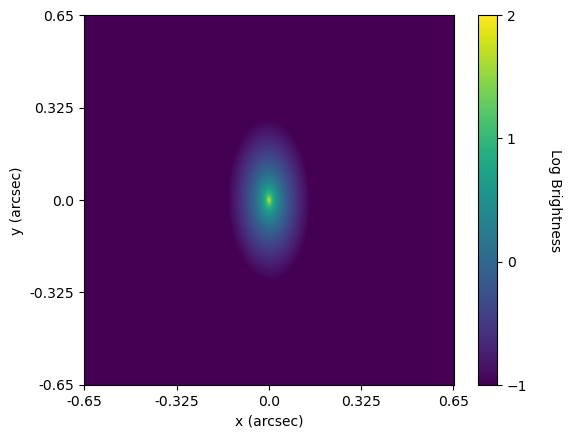

In [39]:
model_cent = Sersic2D(amplitude=1, r_eff = Re_arcsec, n = n_sersic, x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg))

# img is a numpy array of the Sersic profile evaluated at each point in the 2D grid defined by x_arcsec and y_arcsec. 
img = model_cent(x_arcsec, y_arcsec)
log_img = np.log10(img)

fig, ax = plt.subplots()
im = ax.imshow(log_img, origin='lower', interpolation='nearest',
               vmin=-1, vmax=2)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Log Brightness', rotation=270, labelpad=25)
# Set ticks in arcseconds for the x and y axes
ax.set_xticks(np.linspace(0, n_grid-1, 5))
ax.set_xticklabels(np.round(np.linspace(-angular_extent, angular_extent, 5), 3))
ax.set_yticks(np.linspace(0, n_grid-1, 5))
ax.set_yticklabels(np.round(np.linspace(-angular_extent, angular_extent, 5), 3))
cbar.set_ticks([-1, 0, 1, 2])
plt.xlabel('x (arcsec)')
plt.ylabel('y (arcsec)')
plt.show()

In [ ]:
# Focal length of the Coudé focus in meters according to VLT documentation 
f_coude = 399

In [ ]:
print(f"Plate scale at the Coudé focus: {plate_scale_coude*1e-3:.2f} arcsec/mm")

Plate scale at the Coudé focus: 0.52 arcsec/mm


In [ ]:
n_sersic = 3.335 # sersic index, n>0.36
Re_arcsec = 0.101 # half light radius in arcseconds
q_param = 0.514 # projected axis ratio of the galaxy, b/a, where b is the semi-minor axis and a is the semi-major axis. This is used to calculate the effective radius in the direction of the fibre input plane.
# PA = 0 # assumed to be 0 for simplicity, but can be adjusted based on the orientation of the galaxy in the sky.
PA_deg = -88.7
ellip = 1 - q_param # ellipticity of the galaxy, defined as 1 - (b/a)

In [ ]:
# Sersic profile has a scaling constant b_n, for n>0.36, b_n can be approximated as b_n = 2n - 1/3 + 4/(405n) + 46/(25515n^2) + 131/(1148175n^3) 
# - 2194697/(30690717750n^4)
b_n = 2 * n_sersic - 1/3 + 4/(405*n_sersic) + 46/(25515*n_sersic**2) + 131/(1148175*n_sersic**3) - 2194697/(30690717750*n_sersic**4)

In [ ]:
# Sersic2D?

In [ ]:
# Fibre front grid in metres

r_max = 125e-6 # maximum radius of the CLADDING region to be considered in the 2D grid, in meters
n_grid = 1000 

x_1d = np.linspace(-r_max, r_max, n_grid)
y_1d = np.linspace(-r_max, r_max, n_grid)

x, y = np.meshgrid(x_1d, y_1d)

In [ ]:
FOV_test = plate_scale_demag * 2 * r_max
FOV_test_smf = plate_scale_demag * 2 * 5.7e-6
print(f"Test FOV: {FOV_test:.4f} arcsec")
print(f"Test FOV for SMF: {FOV_test_smf:.4f} arcsec")

Test FOV: 1.2956 arcsec
Test FOV for SMF: 0.0591 arcsec


In [ ]:
# Angular grid for the Sersic profile, in radians

# angular_extent = 0.5 # arcsec (I should probably find the FOV of a 125e-6m light bucket)
angular_extent = 1.2956/2 # arcsec, which is half of the FOV of a 125e-6m light bucket at the Coudé focus, based on the plate scale calculated above.

x_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)
y_arcsec_1d = np.linspace(-angular_extent, angular_extent, n_grid)

x_arcsec, y_arcsec = np.meshgrid(x_arcsec_1d, y_arcsec_1d)

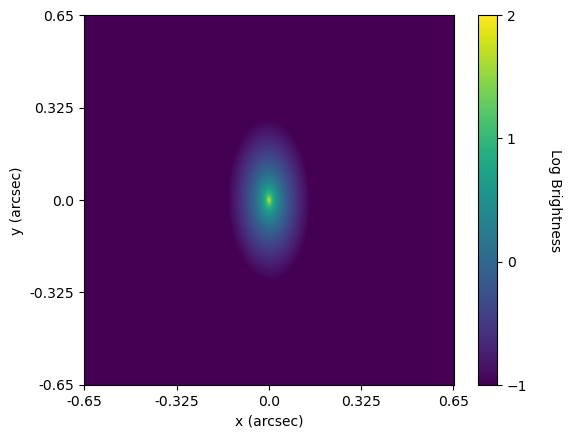

In [ ]:
model_cent = Sersic2D(amplitude=1, r_eff = Re_arcsec, n = n_sersic, x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg))

# img is a numpy array of the Sersic profile evaluated at each point in the 2D grid defined by x_arcsec and y_arcsec. 
img = model_cent(x_arcsec, y_arcsec)
log_img = np.log10(img)

fig, ax = plt.subplots()
im = ax.imshow(log_img, origin='lower', interpolation='nearest',
               vmin=-1, vmax=2)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Log Brightness', rotation=270, labelpad=25)
# Set ticks in arcseconds for the x and y axes
ax.set_xticks(np.linspace(0, n_grid-1, 5))
ax.set_xticklabels(np.round(np.linspace(-angular_extent, angular_extent, 5), 3))
ax.set_yticks(np.linspace(0, n_grid-1, 5))
ax.set_yticklabels(np.round(np.linspace(-angular_extent, angular_extent, 5), 3))
cbar.set_ticks([-1, 0, 1, 2])
plt.xlabel('x (arcsec)')
plt.ylabel('y (arcsec)')
plt.show()

In [40]:
# Only test for a single normalised frequency at r=5.7microns for my first test of decentred position
prepared_smf_mode_5p7micron = prepare_modes_2d(
                                x, y,
                                a=5.7e-6, 
                                NA=NA, 
                                lam0=lam0, 
                                az_sym=False, 
                                mode_case="few_mode"
                            )


In [217]:
# prepare_modes_2d?

In [86]:
# Extract the electric field of the fibre mode at 5.7 microns
E_mode_5p7micron = prepared_smf_mode_5p7micron[0]["E_mode"]


In [41]:
def metres_to_arcseconds(metres, plate_scale_arcsec_per_metre): 
    """
    Convert a physical distance in metres across the fibre plane to arcseconds on the sky.

    Parameters: 
    metres : float
        Physical distance in metres at the fibre plane.
    plate_scale_arcsec_per_metre : float
        Plate scale in arcseconds per metre.

    Returns:
    float
        Distance in arcseconds on the sky.
    """

    # Convert physical distance in metres at the fibre plane to angular distance in radians on the sky
    # 1 radian = 1 metre / (focal_length * demagnification)
    theta_arcseconds = metres * plate_scale_arcsec_per_metre

    return theta_arcseconds

In [42]:
FOV_smf_5p7micron = metres_to_arcseconds(2 * 5.7e-6, plate_scale_demag)
print(f"Test FOV for SMF: {FOV_smf_5p7micron:.4f} arcsec")

Test FOV for SMF: 0.0591 arcsec


In [43]:
# angular_extent_smf = metres_to_arcseconds(5.7e-6, plate_scale_demag)
# x_arcsec_1d_smf = np.linspace(-angular_extent_smf, angular_extent_smf, n_grid)
# y_arcsec_1d_smf = np.linspace(-angular_extent_smf, angular_extent_smf, n_grid)

# x_arcsec_smf, y_arcsec_smf = np.meshgrid(x_arcsec_1d_smf, y_arcsec_1d_smf)

In [44]:
# model_cent = Sersic2D(amplitude=1, r_eff = Re_arcsec, n = n_sersic, x_0=0, y_0=0, ellip=ellip, theta=np.radians(PA_deg))

# # img is a numpy array of the Sersic profile evaluated at each point in the 2D grid defined by x_arcsec and y_arcsec. 
# img = model_cent(x_arcsec_smf, y_arcsec_smf)
# log_img = np.log10(img)

# fig, ax = plt.subplots()
# im = ax.imshow(log_img, origin='lower', interpolation='nearest',
#                vmin=-1, vmax=2)
# cbar = fig.colorbar(im, ax=ax)
# cbar.set_label('Log Brightness', rotation=270, labelpad=25)
# # Set ticks in arcseconds for the x and y axes
# ax.set_xticks(np.linspace(0, n_grid-1, 5))
# ax.set_xticklabels(np.round(np.linspace(-angular_extent, angular_extent, 5), 3))
# ax.set_yticks(np.linspace(0, n_grid-1, 5))
# ax.set_yticklabels(np.round(np.linspace(-angular_extent, angular_extent, 5), 3))
# cbar.set_ticks([-1, 0, 1, 2])
# plt.xlabel('x (arcsec)')
# plt.ylabel('y (arcsec)')
# plt.show()

In [45]:
E_psf, I_psf = diffraction_limited_E_field_at_fibre_2d(x, y, lam0, F_fibre, alpha=0.125, E_S=1.0, decentre=None)

In [94]:
I_sersic = model_cent(x_arcsec, y_arcsec)
phi = np.zeros_like(I_sersic)  # Assuming a flat phase for the source
E_source = np.sqrt(I_sersic) * np.exp(1j * phi)  # Assuming a flat phase for the source

E_source = E_source / np.sqrt(np.sum(np.abs(E_source)**2))  # Normalize the source field

E_gal_focal = fftconvolve(E_source, E_psf, mode='same')  # Convolve the source with the PSF to get the field at the focal plane

I_gal_focal = np.abs(E_gal_focal)**2  # Intensity at the focal plane


In [95]:
E_gal_focal

array([[0.00028951+4.26840102e-17j, 0.00115857+2.86605921e-17j,
        0.00210051+2.59255993e-17j, ..., 0.00344114+1.90832911e-17j,
        0.00223243+2.75890052e-17j, 0.00109981+2.10091741e-17j],
       [0.00150834-4.79739087e-18j, 0.00223061+6.55333254e-18j,
        0.00322114+1.33512348e-17j, ..., 0.00473721+1.53785969e-17j,
        0.00343824+2.20610831e-18j, 0.00222858+1.33703844e-18j],
       [0.00273801-5.43932912e-18j, 0.0034878 -1.22769601e-17j,
        0.00453259-8.92923557e-18j, ..., 0.00622527-8.29907230e-19j,
        0.00483682+6.92226570e-18j, 0.00354926-1.52834142e-17j],
       ...,
       [0.00442162-6.38958634e-18j, 0.00530623-1.60786906e-17j,
        0.00650336-1.75201431e-17j, ..., 0.00670723+2.25410245e-17j,
        0.00532839+3.80899436e-17j, 0.00406795+8.31697408e-18j],
       [0.00306044+3.35925951e-17j, 0.00387097+2.44147218e-17j,
        0.0049911 +2.42618638e-17j, ..., 0.0052031 +3.57414999e-17j,
        0.00391458+4.54953749e-17j, 0.00273737+2.20488095e-17j]

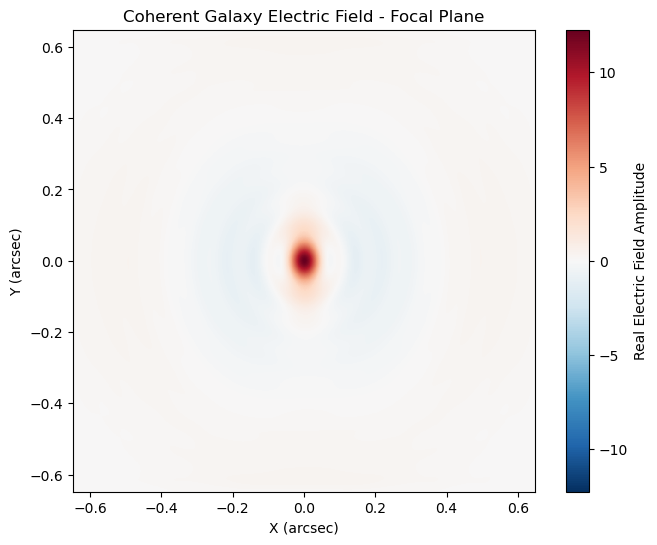

In [96]:
from matplotlib.colors import TwoSlopeNorm

E_real = E_gal_focal.real

# Symmetric colour scale around zero
vmax = np.max(np.abs(E_real))

plt.figure(figsize=(8, 6))

im = plt.imshow(
    E_real,
    origin='lower',
    interpolation='nearest',
    cmap='RdBu_r',  # Positive red, negative blue
    norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
    extent=[
        -angular_extent, angular_extent,
        -angular_extent, angular_extent
    ]
)

plt.title('Coherent Galaxy Electric Field - Focal Plane')
plt.xlabel('X (arcsec)')
plt.ylabel('Y (arcsec)')
plt.colorbar(im, label='Real Electric Field Amplitude')
plt.show()

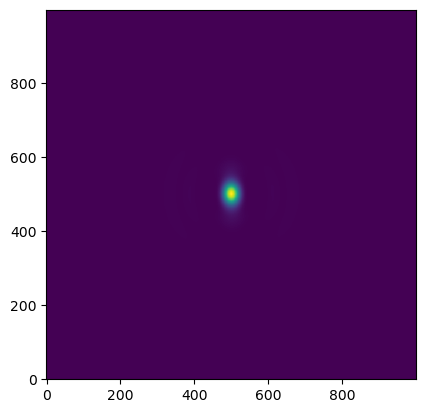

In [97]:
plt.imshow(I_gal_focal.astype(np.float32), origin='lower', interpolation='nearest')

In [99]:
eta_non_opt_vs_core_radius?

Signature:
eta_non_opt_vs_core_radius(
    core_radius_array,
    x,
    y,
    x_1d,
    y_1d,
    lam0,
    NA,
    F_eff=None,
    alpha=0.0,
    decentre=None,
    E_S=1.0,
    mode_case='few_mode',
    l_max=10,
    m_max=5,
    az_sym=True,
    n_jobs=1,
    store_mode_results=True,
)
Docstring:
Calculate the fixed-focal-ratio point-source coupling efficiency
for a range of fibre core radius values.

No focal-ratio optimisation is performed.
The same fixed F_eff is used for every core radius.

The coupling efficiency is calculated from the 2D electric-field
overlap integral through total_eff_2d().

Parameters
----------
core_radius_array : array
    Fibre core radius values [m].

x, y, x_1d, y_1d : arrays
    2D and 1D coordinate grids at the fibre input plane [m].

lam0 : float
    Wavelength [m].

NA : float
    Fibre numerical aperture.

F_eff : float or None
    Fixed effective fibre focal ratio used for all core radii.
    If None, calculate from NA using:
        F_eff = 1 

In [115]:
core_radius_range = np.linspace(2.5e-6, 30e-6, 276)  # Core radius range from 2.5 microns to 30 microns
core_radius_range

array([2.50e-06, 2.60e-06, 2.70e-06, 2.80e-06, 2.90e-06, 3.00e-06,
       3.10e-06, 3.20e-06, 3.30e-06, 3.40e-06, 3.50e-06, 3.60e-06,
       3.70e-06, 3.80e-06, 3.90e-06, 4.00e-06, 4.10e-06, 4.20e-06,
       4.30e-06, 4.40e-06, 4.50e-06, 4.60e-06, 4.70e-06, 4.80e-06,
       4.90e-06, 5.00e-06, 5.10e-06, 5.20e-06, 5.30e-06, 5.40e-06,
       5.50e-06, 5.60e-06, 5.70e-06, 5.80e-06, 5.90e-06, 6.00e-06,
       6.10e-06, 6.20e-06, 6.30e-06, 6.40e-06, 6.50e-06, 6.60e-06,
       6.70e-06, 6.80e-06, 6.90e-06, 7.00e-06, 7.10e-06, 7.20e-06,
       7.30e-06, 7.40e-06, 7.50e-06, 7.60e-06, 7.70e-06, 7.80e-06,
       7.90e-06, 8.00e-06, 8.10e-06, 8.20e-06, 8.30e-06, 8.40e-06,
       8.50e-06, 8.60e-06, 8.70e-06, 8.80e-06, 8.90e-06, 9.00e-06,
       9.10e-06, 9.20e-06, 9.30e-06, 9.40e-06, 9.50e-06, 9.60e-06,
       9.70e-06, 9.80e-06, 9.90e-06, 1.00e-05, 1.01e-05, 1.02e-05,
       1.03e-05, 1.04e-05, 1.05e-05, 1.06e-05, 1.07e-05, 1.08e-05,
       1.09e-05, 1.10e-05, 1.11e-05, 1.12e-05, 1.13e-05, 1.14e

In [ ]:
def total_eff_2d_premade(
    prepared_modes,
    x, y, x_1d, y_1d,
    lam0, F_eff, alpha,
    E_image,
    decentre=None,
    E_S=1.0
):
    """
    Calculates the total 2D coupling efficiency using precomputed fibre modes.
    Only E_image changes with focal ratio F.

    Parameters:
    prepared_modes: A list of dictionaries containing precomputed fibre mode fields and their properties.
    x, y: 2D coordinate arrays at the fibre input plane [m]
    x_1d, y_1d: 1D coordinate arrays used to make the 2D grid [m]
    lam0: Wavelength [m]
    F_eff: Effective focal ratio to be optimised
    alpha: Divergence angle [rad]
    decentre: Decentre of the image field [m]
    E_S: Source electric field amplitude [V/m]
    """

    # E_image, I_image = diffraction_limited_E_field_at_fibre_2d(
    #     x, y,
    #     lam0=lam0,
    #     F_eff=F_eff,
    #     alpha=alpha,
    #     E_S=E_S,
    #     decentre=decentre
    # )

    # begin with zero efficiency when we haven't started accumulating eta for any modes
    total = 0.0
    mode_results = [] # array of dictionaries containing mode results

    # for each existing modes in the prepared_modes list, calculate eta at that mode
    for mode in prepared_modes:
        eta, num, den = coupling_efficiency_2d(
            E_image,
            mode["E_mode"],
            x_1d,
            y_1d
        )

        total += eta # accumulate coupling efficiency at each mode to the total coupling efficiency

        mode_results.append({
            "l": mode["l"],
            "m": mode["m"],
            "cutoff_V": mode["cutoff_V"],
            "X_root": mode["X_root"],
            "Y_root": mode["Y_root"],
            "angular": mode["angular"],
            "eta": eta
        })

    return total, mode_results


def eta_non_opt_vs_core_radius_premade(
    core_radius_array,
    E_image, 
    x, y, x_1d, y_1d,
    lam0,
    NA,
    F_eff=None,
    alpha=0.0,
    decentre=None,
    E_S=1.0,
    mode_case="few_mode",
    l_max=10,
    m_max=5,
    az_sym=False,
    n_jobs=1,
    store_mode_results=True,
): 
    """
    Calculate the fixed-focal-ratio point-source coupling efficiency
    for a range of fibre core radius values.

    No focal-ratio optimisation is performed.
    The same fixed F_eff is used for every core radius.

    The coupling efficiency is calculated from the 2D electric-field
    overlap integral through total_eff_2d().

    Parameters
    ----------
    core_radius_array : array
        Fibre core radius values [m].

    x, y, x_1d, y_1d : arrays
        2D and 1D coordinate grids at the fibre input plane [m].

    lam0 : float
        Wavelength [m].

    NA : float
        Fibre numerical aperture.

    F_eff : float or None
        Fixed effective fibre focal ratio used for all core radii.
        If None, calculate from NA using:
            F_eff = 1 / (2 tan(arcsin(NA)))

    alpha : float
        Central obstruction ratio.

    decentre : tuple, list, or None
        Point-source decentre position at the fibre input plane.
        If None, the point source is centred.

    E_S : float
        Electric-field amplitude of the point source.

    mode_case : str
        Fibre mode case, for example "smf" or "few_mode".

    az_sym : bool
        Whether to include only azimuthally symmetric modes.

    n_jobs : int
        Number of parallel workers. Use n_jobs=1 for serial.

    store_mode_results : bool
        If True, store the per-mode coupling results for every core radius.
        If False, only return total coupling efficiency.

    Returns
    -------
    eta_total_non_opt_array : 1D numpy array
        Total point-source coupling efficiency for each core radius.

    mode_results_non_opt_array : list
        Per-mode coupling results for each core radius.
        If store_mode_results=False, this is None.

    V_array : 1D numpy array
        Normalised frequency values corresponding to core_radius_array.
    """

    if F_eff is None:
        F_eff = 1 / (2 * np.tan(np.arcsin(NA)))

    core_radius_array = np.asarray(core_radius_array)

    V_array = 2 * np.pi * core_radius_array * NA / lam0

    n_total = len(core_radius_array)

    def run_one_radius(a):
        prepared_modes = prepare_modes_2d(
            x, y,
            a=a,
            NA=NA,
            lam0=lam0,
            az_sym=az_sym,
            mode_case=mode_case, 
            l_max=l_max,
            m_max=m_max
        )

        eta_tot, mode_results = total_eff_2d_premade(
            prepared_modes=prepared_modes,
            x=x,
            y=y,
            x_1d=x_1d,
            y_1d=y_1d,
            lam0=lam0,
            F_eff=F_eff,
            alpha=alpha,
            E_image=E_image,
            decentre=decentre,
            E_S=E_S
        )

        if store_mode_results:
            return eta_tot, mode_results
        else:
            return eta_tot, None

    if n_jobs == 1:
        eta_total_non_opt_array = []
        mode_results_non_opt_array = [] if store_mode_results else None

        checkpoints = {
            max(1, int(np.ceil(n_total * p / 10)))
            for p in range(1, 11)
        }

        for i, a in enumerate(core_radius_array, start=1):
            eta_tot, mode_results = run_one_radius(a)

            eta_total_non_opt_array.append(eta_tot)

            if store_mode_results:
                mode_results_non_opt_array.append(mode_results)

            if i in checkpoints:
                percent = int(round(100 * i / n_total))
                print(f"{percent}% complete ({i}/{n_total})")

    else:
        results = Parallel(n_jobs=n_jobs, verbose=10)(
            delayed(run_one_radius)(a)
            for a in core_radius_array
        )

        eta_total_non_opt_array = [row[0] for row in results]

        if store_mode_results:
            mode_results_non_opt_array = [row[1] for row in results]
        else:
            mode_results_non_opt_array = None

    eta_total_non_opt_array = np.asarray(eta_total_non_opt_array)

    return eta_total_non_opt_array, mode_results_non_opt_array, V_array

In [235]:
eta_tot, mode_res, V_array = eta_non_opt_vs_core_radius_premade(
                                                            core_radius_range, 
                                                            E_gal_focal, 
                                                            x, y, x_1d, y_1d,
                                                            lam0,
                                                            NA,
                                                            F_eff=F_fibre,
                                                            alpha=alpha_vlt,
                                                            decentre=None,
                                                            E_S=1.0,
                                                            mode_case="few_mode",
                                                            l_max=10,
                                                            m_max=5,
                                                            az_sym=False,
                                                            n_jobs=4,
                                                            store_mode_results=True)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    1.5s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    2.0s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    3.0s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    3.5s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    4.8s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    9.6s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   12.7s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   17.0s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:   26.6s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:   36.5s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:   49.6s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:  1.5min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  2.0min
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed: 20.1min
[Parallel(

Text(0, 0.5, 'Total Coupling Efficiency')

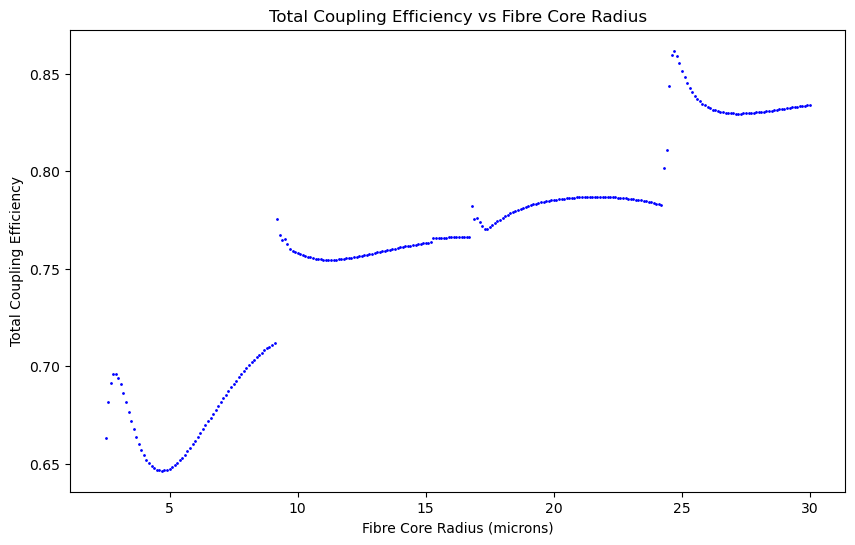

In [236]:
plt.figure(figsize=(10, 6))
plt.scatter(core_radius_range*1e6, eta_tot, color='blue', label='Total Coupling Efficiency', s=1)
plt.title('Total Coupling Efficiency vs Fibre Core Radius')
plt.xlabel('Fibre Core Radius (microns)')
plt.ylabel('Total Coupling Efficiency')

In [ ]:
# E_source_90rot = np.rot90(E_source)  # Rotate the source field by 90 degrees
# E_gal_focal_90rot = fftconvolve(E_source_90rot, E_psf, mode='same')  # Convolve the rotated source with the PSF to get the field at the focal plane

In [220]:
# eta_tot, mode_res, V_array = eta_non_opt_vs_core_radius_premade(
#                                                             core_radius_range, 
#                                                             E_gal_focal_90rot, 
#                                                             x, y, x_1d, y_1d,
#                                                             lam0,
#                                                             NA,
#                                                             F_eff=F_fibre,
#                                                             alpha=alpha_vlt,
#                                                             decentre=None,
#                                                             E_S=1.0,
#                                                             mode_case="few_mode",
#                                                             l_max=10,
#                                                             m_max=5,
#                                                             az_sym=True,
#                                                             n_jobs=4,
#                                                             store_mode_results=True)

In [221]:
# plt.figure(figsize=(10, 6))
# plt.scatter(core_radius_range*1e6, eta_tot, color='blue', label='Total Coupling Efficiency', s=1)
# plt.title('Total Coupling Efficiency vs Fibre Core Radius')
# plt.xlabel('Fibre Core Radius (microns)')
# plt.ylabel('Total Coupling Efficiency')

In [181]:
def extract_mode_efficiency_by_radius(
    mode_results,
    core_radius_array
):
    """
    Extract the coupling efficiency of each individual LP mode
    as a function of fibre core radius.

    Parameters
    ----------
    mode_results : list
        List of per-mode results returned by
        eta_non_opt_vs_core_radius_premade().

        Each element corresponds to one fibre core radius
        and contains dictionaries describing the supported modes.

    core_radius_array : array
        Fibre core radii [m].

    Returns
    -------
    mode_eta_dict : dict
        Dictionary containing coupling efficiency arrays
        for each LP mode.

        Example:
            {
                "LP01": array([...]),
                "LP02": array([...]),
                "LP11 cos": array([...]),
                "LP11 sin": array([...])
            }
    """

    n_radius = len(core_radius_array)

    if mode_results is None:
        raise ValueError(
            "Mode results were not stored. "
            "Rerun with store_mode_results=True."
        )

    if len(mode_results) != n_radius:
        raise ValueError(
            "mode_results and core_radius_array must "
            "have the same length."
        )

    mode_eta_dict = {}

    # ========================================================
    # Loop through every fibre core radius
    # ========================================================

    for i, modes_at_radius in enumerate(mode_results):

        # Each radius supports a different number of LP modes,
        # depending on its V-number.
        #
        # Each mode is stored as a dictionary containing
        # its azimuthal order l, radial order m, angular
        # component, and coupling efficiency eta.

        for mode in modes_at_radius:

            l = int(mode["l"])
            m = int(mode["m"])
            angular = mode["angular"]
            eta = mode["eta"]

            # Construct a readable mode label.
            #
            # LP01, LP02, ... have no separate angular components.
            #
            # Asymmetric modes have cosine and sine components,
            # which are stored separately.

            if l == 0:
                label = f"LP{l}{m}"
            else:
                label = f"LP{l}{m} {angular}"

            # If this mode has not appeared before, create
            # a new array with one entry per fibre radius.
            #
            # np.nan indicates that the mode is not supported
            # at that particular radius.
            #
            # Using NaN rather than zero prevents Matplotlib
            # from drawing the curve below the mode cutoff.

            if label not in mode_eta_dict:
                mode_eta_dict[label] = np.full(
                    n_radius,
                    np.nan
                )

            # Store the coupling efficiency at this radius.

            mode_eta_dict[label][i] = eta

    return mode_eta_dict

In [202]:
def plot_coherent_source_efficiency_by_mode(
    core_radius_array,
    eta_total,
    mode_results,
    lam0,
    NA,
    mode_group="symmetric",
    title=None,
    total_label=r"Total coherent coupling efficiency, $\eta_{\mathrm{gal}}$",
    total_color="black",
):
    """
    Plot coherent extended-source coupling efficiency as a function
    of fibre core radius, including individual LP mode contributions.

    Parameters
    ----------
    core_radius_array : array
        Fibre core radii [m].

    eta_total : array
        Total coherent coupling efficiency at each core radius.

    mode_results : list
        Per-mode coupling results returned by
        eta_non_opt_vs_core_radius_premade().

    lam0 : float
        Wavelength [m].

    NA : float
        Fibre numerical aperture.

    mode_group : str
        "symmetric"  -> l = 0 modes (LP01, LP02, ...)
        "asymmetric" -> l > 0 modes (LP11, LP21, ...)
        "all"        -> all supported modes.

    Returns
    -------
    mode_eta_dict : dict
        Coupling efficiency arrays for the selected LP modes.

    mode_lines : dict
        Matplotlib line objects for individual LP modes.
    """

    # =========================================================
    # 1. Extract individual LP mode efficiencies
    # =========================================================

    mode_eta_dict = extract_mode_efficiency_by_radius(
        mode_results=mode_results,
        core_radius_array=core_radius_array
    )

    # Select symmetric, asymmetric, or all LP modes.
    if mode_group == "symmetric":
        mode_eta_dict = {
            label: eta
            for label, eta in mode_eta_dict.items()
            if " " not in label
        }

    elif mode_group == "asymmetric":
        mode_eta_dict = {
            label: eta
            for label, eta in mode_eta_dict.items()
            if (" cos" in label) or (" sin" in label)
        }

    elif mode_group != "all":
        raise ValueError(
            "mode_group must be 'symmetric', 'asymmetric', or 'all'."
        )

    # =========================================================
    # 2. Set up figure and plot total coupling efficiency
    # =========================================================

    radius_um = np.asarray(core_radius_array) * 1e6

    fig, ax1 = plt.subplots(figsize=(10, 6))

    ax1.plot(
        radius_um,
        eta_total,
        color=total_color,
        linewidth=2.2,
        label=total_label
    )

    # =========================================================
    # 3. Shade the single-mode region
    # =========================================================

    # Convert between fibre core radius [µm] and V-number.
    def V_to_radius_um(V):
        return V * lam0 / (2 * np.pi * NA) * 1e6

    def radius_um_to_V(radius_um):
        return 2 * np.pi * radius_um * 1e-6 * NA / lam0

    ax1.axvspan(
        V_to_radius_um(1.2),
        V_to_radius_um(2.405),
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$"
    )

    # =========================================================
    # 4. Assign colours to LP mode families
    # =========================================================

    # Cosine and sine components of the same LP mode
    # share the same colour.
    base_modes = sorted({
        label.split()[0]
        for label in mode_eta_dict
    })

    colours = plt.cm.turbo(
        np.linspace(0, 1, max(len(base_modes), 1))
    )

    colour_dict = dict(zip(base_modes, colours))

    # =========================================================
    # 5. Plot individual LP mode contributions
    # =========================================================

    mode_lines = {}

    for label, eta_mode in mode_eta_dict.items():

        base_mode = label.split()[0]

        # Cosine components and symmetric modes are dashed.
        # Sine components are dotted.
        linestyle = ":" if label.endswith("sin") else "--"

        line, = ax1.plot(
            radius_um,
            eta_mode,
            color=colour_dict[base_mode],
            linestyle=linestyle,
            linewidth=1.7,
            alpha=0.9,
            label=label
        )

        mode_lines[label] = line

    # =========================================================
    # 6. Axis labels and formatting
    # =========================================================

    ax1.set_xlabel(
        "Core radius (µm)",
        fontsize=16,
        labelpad=8
    )

    ax1.set_ylabel(
        r"Coherent coupling efficiency, $\eta_{\mathrm{gal}}$",
        fontsize=16,
        labelpad=8
    )

    if title is not None:
        ax1.set_title(title, fontsize=15, pad=15)

    ax1.tick_params(axis="both", labelsize=14)
    ax1.minorticks_on()
    ax1.grid(True, alpha=0.3)

    ax1.set_xlim(radius_um.min(), radius_um.max())
    ax1.set_ylim(0, 1)

    # =========================================================
    # 7. Top x-axis: normalised frequency V
    # =========================================================

    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(radius_um_to_V, V_to_radius_um)
    )

    ax_top.set_xlabel(
        "Normalised frequency, V",
        fontsize=14,
        labelpad=8
    )

    ax_top.tick_params(axis="x", labelsize=14)
    ax_top.minorticks_on()

    # =========================================================
    # 8. Legend
    # =========================================================

    handles, labels = ax1.get_legend_handles_labels()

    n_legend_rows = 4
    n_legend_cols = max(
        1,
        math.ceil(len(labels) / n_legend_rows)
    )

    ax1.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.0, 1.0, 1.0, 0.0),
        bbox_transform=ax1.transAxes,
        ncol=n_legend_cols,
        mode="expand",
        fontsize=8,
        frameon=True,
        framealpha=0.85,
        columnspacing=0.8,
        handlelength=1.6,
        handletextpad=0.4,
        borderaxespad=0.4
    )

    plt.tight_layout()
    plt.show()

    return mode_eta_dict, mode_lines

In [250]:
def plot_galaxy_efficiency(
    core_radius_array,
    eta_total,
    results,
    NA,
    lam0,
    title,
    total_label,
    total_color="black",
):
    core_radius_array = np.asarray(core_radius_array)
    radius_um = core_radius_array * 1e6

    def get_mode_label(mode):
        label = f"LP{mode['l']}{mode['m']}"

        if mode["l"] != 0:
            label += f" {mode['angular']}"

        return label

    mode_labels = sorted({
        get_mode_label(mode)
        for radius_modes in results
        for mode in radius_modes
    })

    mode_eta_dict = {}

    for label in mode_labels:
        mode_eta_dict[label] = np.array([
            next(
                (
                    mode["eta"]
                    for mode in radius_modes
                    if get_mode_label(mode) == label
                ),
                np.nan,
            )
            for radius_modes in results
        ])

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Total efficiency
    ax1.plot(
        radius_um,
        eta_total,
        color=total_color,
        linewidth=2,
        label=total_label,
    )

    # Individual modes
    colours = plt.cm.turbo(
        np.linspace(0, 1, max(len(mode_labels), 1))
    )

    mode_lines = {}

    for colour, label in zip(colours, mode_labels):
        line, = ax1.plot(
            radius_um,
            mode_eta_dict[label],
            color=colour,
            linestyle="dashed",
            linewidth=1.6,
            label=label,
        )

        mode_lines[label] = line

    # Single-mode region
    radius_V_1_2_um = 1.2 * lam0 / (2 * np.pi * NA) * 1e6
    radius_V_2_405_um = 2.405 * lam0 / (2 * np.pi * NA) * 1e6

    ax1.axvspan(
        radius_V_1_2_um,
        radius_V_2_405_um,
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$",
    )

    ax1.set_xlabel("Core radius (µm)", fontsize=14)
    ax1.set_ylabel("Coupling efficiency", fontsize=14)
    ax1.set_title(title, fontsize=16, pad=15)

    ax1.tick_params(axis="both", labelsize=12)
    ax1.minorticks_on()
    ax1.grid(True, alpha=0.3)

    # Top V axis
    def radius_um_to_V(radius_um):
        return 2 * np.pi * np.asarray(radius_um) * 1e-6 * NA / lam0

    def V_to_radius_um(V):
        return np.asarray(V) * lam0 / (2 * np.pi * NA) * 1e6

    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(radius_um_to_V, V_to_radius_um),
    )

    ax_top.set_xlabel("Normalised frequency, V", fontsize=14)
    ax_top.tick_params(axis="x", labelsize=12)

    ax1.legend(
        loc="lower left",
        fontsize=7,
        frameon=True,
        framealpha=0.85,
        ncol=3,
    )

    plt.tight_layout()
    plt.show()

    return mode_eta_dict, mode_lines

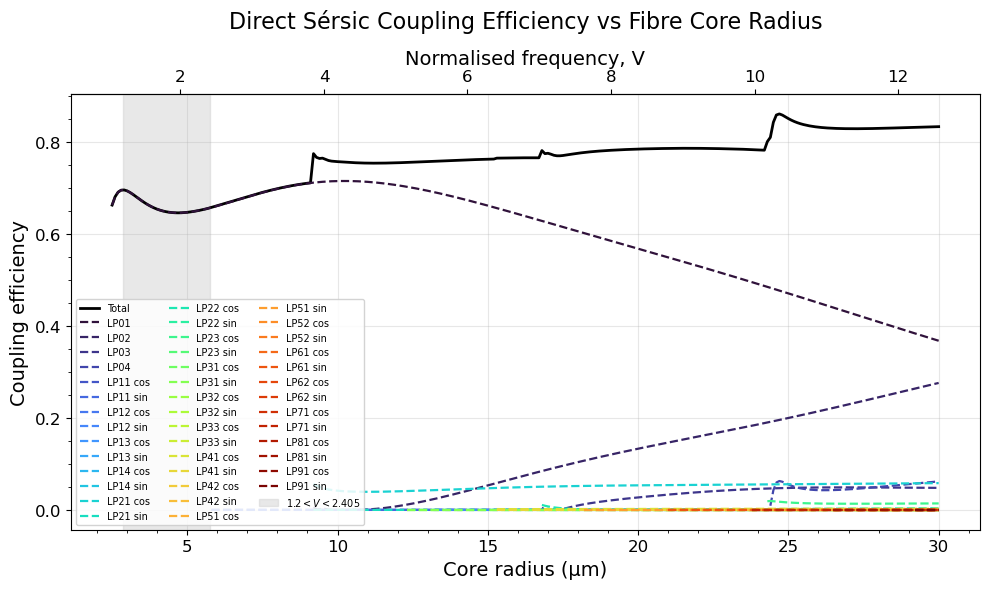

In [251]:
mode_eta, mode_lines = plot_galaxy_efficiency(
    core_radius_array=core_radius_range,
    eta_total=eta_tot,
    results=mode_res,
    NA=NA,
    lam0=lam0,
    title="Direct Sérsic Coupling Efficiency vs Fibre Core Radius",
    total_label="Total ",
    total_color="black",
)

In [162]:
E_gal_focal_test = fftconvolve(E_psf, I_gal_focal / np.max(I_gal_focal), mode='same')  # Convolve the source with the PSF to get the field at the focal plane

In [ ]:
def plot_galaxy_efficiency(
    core_radius_array,
    eta_total,
    results,
    NA,
    lam0,
    title,
    total_label,
    total_color="black",
):
    core_radius_array = np.asarray(core_radius_array)
    radius_um = core_radius_array * 1e6

    def get_mode_label(mode):
        label = f"LP{mode['l']}{mode['m']}"

        if mode["l"] != 0:
            label += f" {mode['angular']}"

        return label

    mode_labels = sorted({
        get_mode_label(mode)
        for radius_modes in results
        for mode in radius_modes
    })

    mode_eta_dict = {}

    for label in mode_labels:
        mode_eta_dict[label] = np.array([
            next(
                (
                    mode["eta"]
                    for mode in radius_modes
                    if get_mode_label(mode) == label
                ),
                np.nan,
            )
            for radius_modes in results
        ])

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Total efficiency
    ax1.plot(
        radius_um,
        eta_total,
        color=total_color,
        linewidth=2,
        label=total_label,
    )

    # Individual modes
    colours = plt.cm.turbo(
        np.linspace(0, 1, max(len(mode_labels), 1))
    )

    mode_lines = {}

    for colour, label in zip(colours, mode_labels):
        line, = ax1.plot(
            radius_um,
            mode_eta_dict[label],
            color=colour,
            linestyle="dashed",
            linewidth=1.6,
            label=label,
        )

        mode_lines[label] = line

    # Single-mode region
    radius_V_1_2_um = 1.2 * lam0 / (2 * np.pi * NA) * 1e6
    radius_V_2_405_um = 2.405 * lam0 / (2 * np.pi * NA) * 1e6

    ax1.axvspan(
        radius_V_1_2_um,
        radius_V_2_405_um,
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$",
    )

    ax1.set_xlabel("Core radius (µm)", fontsize=14)
    ax1.set_ylabel("Coupling efficiency", fontsize=14)
    ax1.set_title(title, fontsize=16, pad=15)

    ax1.tick_params(axis="both", labelsize=12)
    ax1.minorticks_on()
    ax1.grid(True, alpha=0.3)

    # Top V axis
    def radius_um_to_V(radius_um):
        return 2 * np.pi * np.asarray(radius_um) * 1e-6 * NA / lam0

    def V_to_radius_um(V):
        return np.asarray(V) * lam0 / (2 * np.pi * NA) * 1e6

    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(radius_um_to_V, V_to_radius_um),
    )

    ax_top.set_xlabel("Normalised frequency, V", fontsize=14)
    ax_top.tick_params(axis="x", labelsize=12)

    ax1.legend(
        loc="upper left",
        fontsize=9,
        frameon=True,
        framealpha=0.85,
        ncol=3,
    )

    plt.tight_layout()
    plt.show()

    return mode_eta_dict, mode_lines

In [168]:
# Normalise I_sersic before convolving
I_sersic_norm = I_sersic / np.max(I_sersic)
E_gal_focal_test = fftconvolve(I_sersic_norm, E_psf, mode='same')
# Normalise E_gal_focal_test
# E_gal_focal_test = E_gal_focal_test / np.sqrt(np.sum(np.abs(E_gal_focal_test)**2))  # Normalize the field
I_gal_focal_test = np.abs(E_gal_focal_test)**2

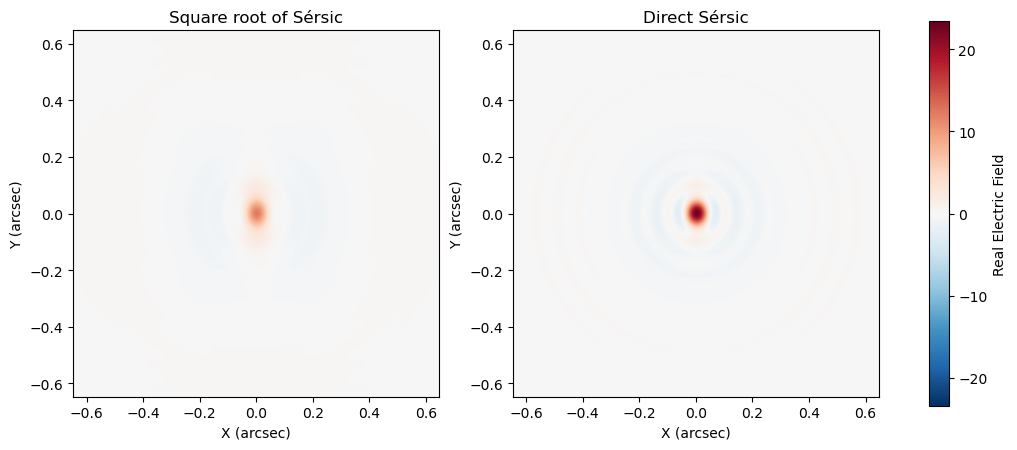

In [169]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

vmax = max(
    np.max(np.abs(E_gal_focal.real)),
    np.max(np.abs(E_gal_focal_test.real))
)

for axis, E, title in zip(
    ax,
    [E_gal_focal, E_gal_focal_test],
    ['Square root of Sérsic', 'Direct Sérsic']
):
    im = axis.imshow(
        E.real,
        origin='lower',
        cmap='RdBu_r',
        vmin=-vmax,
        vmax=vmax,
        extent=[
            -angular_extent, angular_extent,
            -angular_extent, angular_extent
        ]
    )

    axis.set_title(title)
    axis.set_xlabel('X (arcsec)')
    axis.set_ylabel('Y (arcsec)')

fig.colorbar(im, ax=ax, label='Real Electric Field')
plt.show()

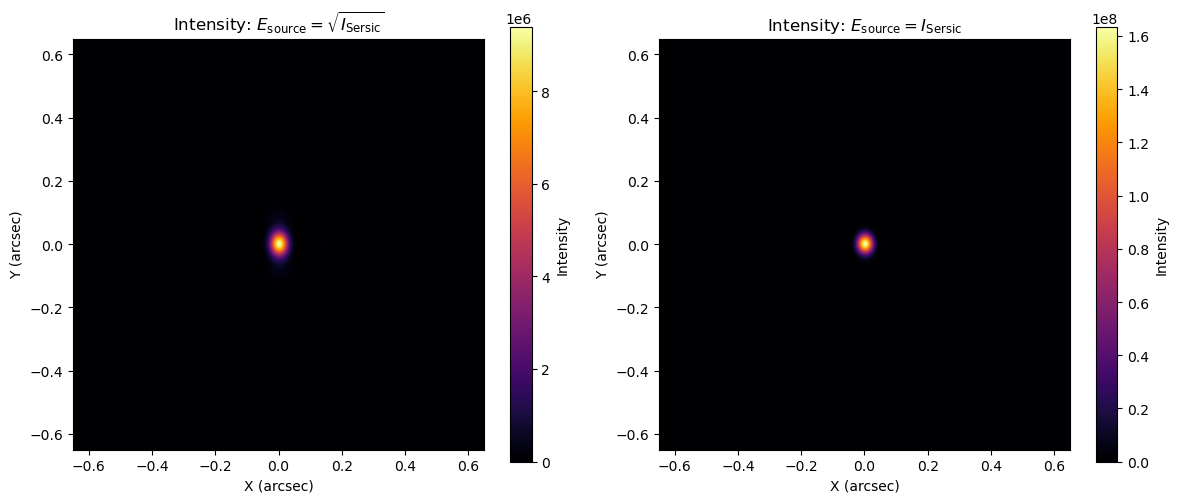

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

extent = [
    -angular_extent, angular_extent,
    -angular_extent, angular_extent
]

# Intensity from sqrt(I_sersic) source field
im1 = ax[0].imshow(
    I_gal_focal,
    origin='lower',
    cmap='inferno',
    extent=extent
)
ax[0].set_title(r'Intensity: $E_{\rm source}=\sqrt{I_{\rm Sersic}}$')
ax[0].set_xlabel('X (arcsec)')
ax[0].set_ylabel('Y (arcsec)')
ax[0].set_aspect('equal')
fig.colorbar(im1, ax=ax[0], label='Intensity')

# Intensity from direct I_sersic source field
im2 = ax[1].imshow(
    I_gal_focal_test,
    origin='lower',
    cmap='inferno',
    extent=extent
)
ax[1].set_title(r'Intensity: $E_{\rm source}=I_{\rm Sersic}$')
ax[1].set_xlabel('X (arcsec)')
ax[1].set_ylabel('Y (arcsec)')
ax[1].set_aspect('equal')
fig.colorbar(im2, ax=ax[1], label='Intensity')

plt.tight_layout()
plt.show()

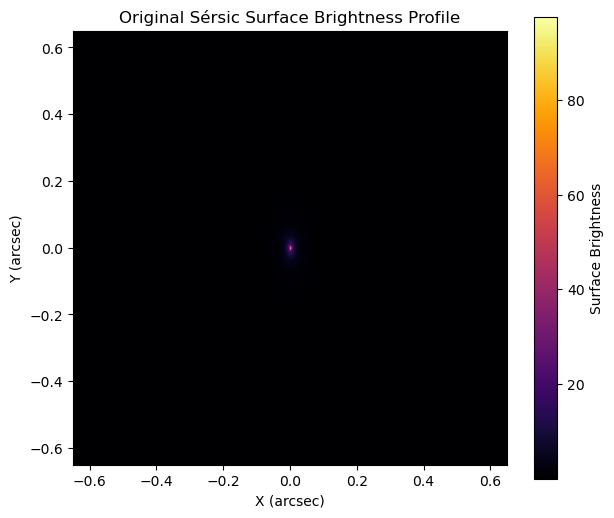

In [65]:
# plot img

plt.figure(figsize=(7, 6))

im = plt.imshow(
    img,
    origin='lower',
    interpolation='nearest',
    cmap='inferno',
    extent=[
        -angular_extent, angular_extent,
        -angular_extent, angular_extent
    ]
)

plt.title('Original Sérsic Surface Brightness Profile')
plt.xlabel('X (arcsec)')
plt.ylabel('Y (arcsec)')
plt.colorbar(im, label='Surface Brightness')

plt.show()

In [234]:
eta_tot_test, mode_res_test, V_array_test = eta_non_opt_vs_core_radius_premade(
                                                            core_radius_range, 
                                                            E_gal_focal_test, 
                                                            x, y, x_1d, y_1d,
                                                            lam0,
                                                            NA,
                                                            F_eff=F_fibre,
                                                            alpha=alpha_vlt,
                                                            decentre=None,
                                                            E_S=1.0,
                                                            mode_case="few_mode",
                                                            l_max=10,
                                                            m_max=5,
                                                            az_sym=False,
                                                            n_jobs=4,
                                                            store_mode_results=True)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    2.2s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    2.6s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    3.1s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    3.5s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    4.3s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    7.6s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:    9.8s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   12.6s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:   19.5s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:   26.5s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:   36.9s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:   53.4s
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:  1.3min
/Users/tliu/.conda/envs/oh_suppression_env/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: 

Text(0, 0.5, 'Total Coupling Efficiency')

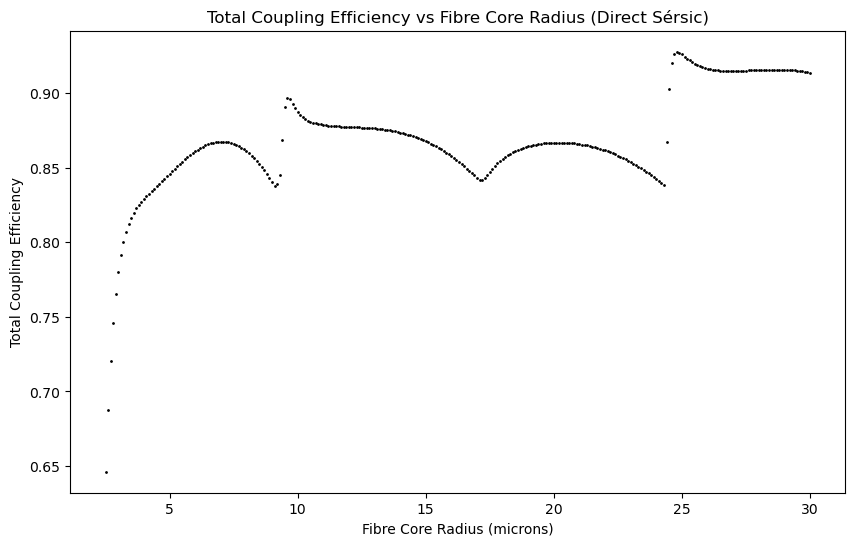

In [120]:
plt.figure(figsize=(10, 6))
plt.scatter(core_radius_range*1e6, eta_tot_test, color='k', label='Total Coupling Efficiency (Direct Sérsic)', s=1)
plt.title('Total Coupling Efficiency vs Fibre Core Radius (Direct Sérsic)')
plt.xlabel('Fibre Core Radius (microns)')
plt.ylabel('Total Coupling Efficiency')

In [69]:
# ============================================================
# Fibre front-face coordinates
# ============================================================

r_max = 125e-6  # Half-width of computational region [m]
n_grid = 1000

# Uniform FFT-centred grid
dx = 2 * r_max / n_grid

x_1d = (np.arange(n_grid) - n_grid // 2) * dx
y_1d = (np.arange(n_grid) - n_grid // 2) * dx

x, y = np.meshgrid(x_1d, y_1d)

# ============================================================
# Corresponding angular coordinates on the sky
# ============================================================

x_arcsec = x * plate_scale_demag
y_arcsec = y * plate_scale_demag

angular_extent = r_max * plate_scale_demag

print(f"Angular half-width: {angular_extent:.4f} arcsec")
print(f"Focal-plane spacing: {dx*1e6:.4f} µm")

Angular half-width: 0.6478 arcsec
Focal-plane spacing: 0.2500 µm


In [ ]:
f_eff = rad_to_arcsec / plate_scale_demag  # Effective focal length of the demagnified fibre input plane [m]

# Fourier conjugate pupil coordinates [m]
# this is the spatial frequency in cycles per metre, which is then converted to a pupil coordinate in metres by multiplying by the wavelength and effective focal length
p_1d = np.fft.fftshift(np.fft.fftfreq(n_grid, d=dx)) * lam0 * f_eff

# Define the 2D pupil coordinates using meshgrid, we need a new grid for the pupil plane, 
# which is the Fourier conjugate of the focal plane. 
# The pupil coordinates are in metres, and they represent the physical size of the pupil in the telescope.
PX, PY = np.meshgrid(p_1d, p_1d)

# VLT Pupil transmission
R_pupil = np.sqrt(PX**2 + PY**2)

# Pupil function: 1 inside the annular pupil, 0 outside
pupil_function = (R_pupil <= D_M1 / 2) & (R_pupil >= D_obstruction / 2)
# Electric field at the pupil plane, normalised to unit norm
E_pupil = pupil_function.astype(complex)
E_pupil /= np.linalg.norm(E_pupil)  # Normalise the pupil field

print(f"Effective focal length: {f_eff:.3f} m")
print(f"Pupil pixel spacing: {(p_1d[1]-p_1d[0]):.4f} m")

Effective focal length: 39.799 m
Pupil pixel spacing: 0.2388 m


In [ ]:
# Intensity of the source in the focal plane
brightness = I_sersic / np.sum(I_sersic)  # Normalise the brightness to have a total of 1
phi_source = np.zeros_like(I_sersic)  # Assuming a flat phase for the source

# Electric field of the source in the focal plane, normalised to unit norm
E_source = np.sqrt(brightness) * np.exp(1j * phi_source)
# Coherent superposition of all angular phase tilts, norm ortho is important to ensure that the total power is preserved in the Fourier transform. 
# The factor of n_grid accounts for the scaling of the discrete Fourier transform, and the double fftshift centers the zero frequency component in the output array.
galaxy_pupil_factor = n_grid * np.fft.fftshift(
    np.fft.ifft2(
        np.fft.ifftshift(E_source),
        norm='ortho'
    )
)
# Apply telescopic pupil function to the galaxy pupil factor
E_gal_pupil = galaxy_pupil_factor * E_pupil

In [74]:
E_gal_focal = np.fft.fftshift(
    np.fft.fft2(
        np.fft.ifftshift(E_gal_pupil),
        norm='ortho'
    )
)

# Resulting coherent intensity
I_gal_focal = np.abs(E_gal_focal)**2

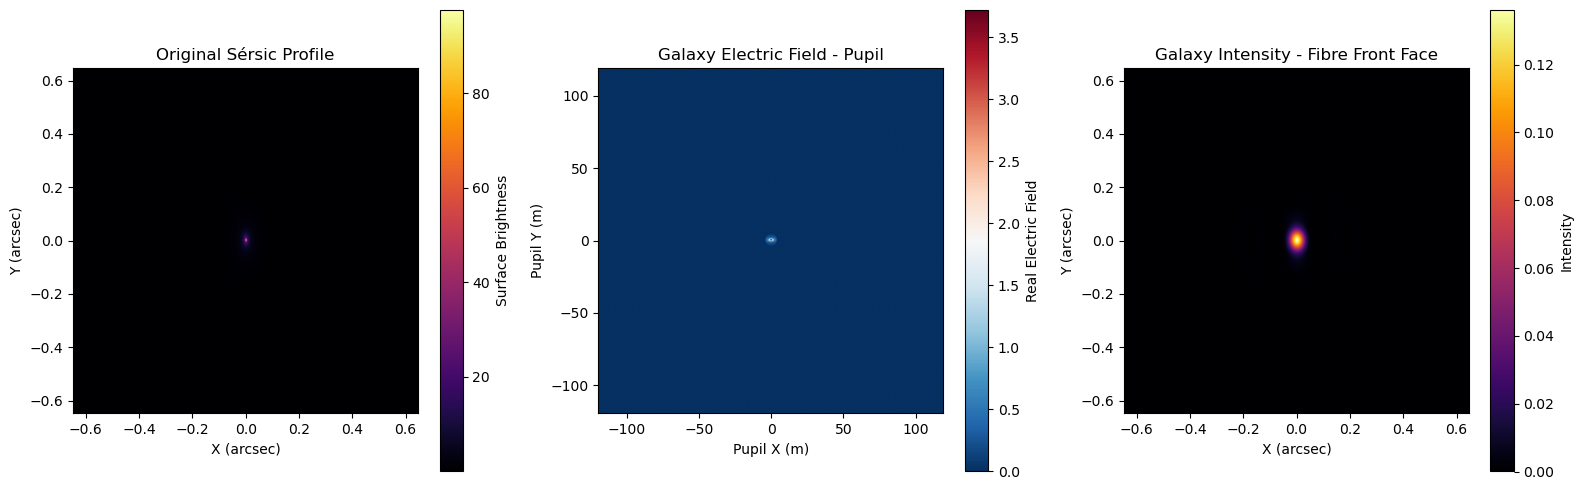

In [75]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

extent_sky = [
    x_arcsec.min(), x_arcsec.max(),
    y_arcsec.min(), y_arcsec.max()
]

extent_pupil = [
    p_1d.min(), p_1d.max(),
    p_1d.min(), p_1d.max()
]

# Original Sérsic intensity
im0 = ax[0].imshow(
    I_sersic,
    origin='lower',
    cmap='inferno',
    extent=extent_sky
)
ax[0].set_title('Original Sérsic Profile')
ax[0].set_xlabel('X (arcsec)')
ax[0].set_ylabel('Y (arcsec)')
fig.colorbar(im0, ax=ax[0], label='Surface Brightness')

# Galaxy electric field at telescope pupil
im1 = ax[1].imshow(
    E_gal_pupil.real,
    origin='lower',
    cmap='RdBu_r',
    extent=extent_pupil
)
ax[1].set_title('Galaxy Electric Field - Pupil')
ax[1].set_xlabel('Pupil X (m)')
ax[1].set_ylabel('Pupil Y (m)')
fig.colorbar(im1, ax=ax[1], label='Real Electric Field')

# Galaxy intensity at fibre front face
im2 = ax[2].imshow(
    I_gal_focal,
    origin='lower',
    cmap='inferno',
    extent=extent_sky
)
ax[2].set_title('Galaxy Intensity - Fibre Front Face')
ax[2].set_xlabel('X (arcsec)')
ax[2].set_ylabel('Y (arcsec)')
fig.colorbar(im2, ax=ax[2], label='Intensity')

plt.tight_layout()
plt.show()

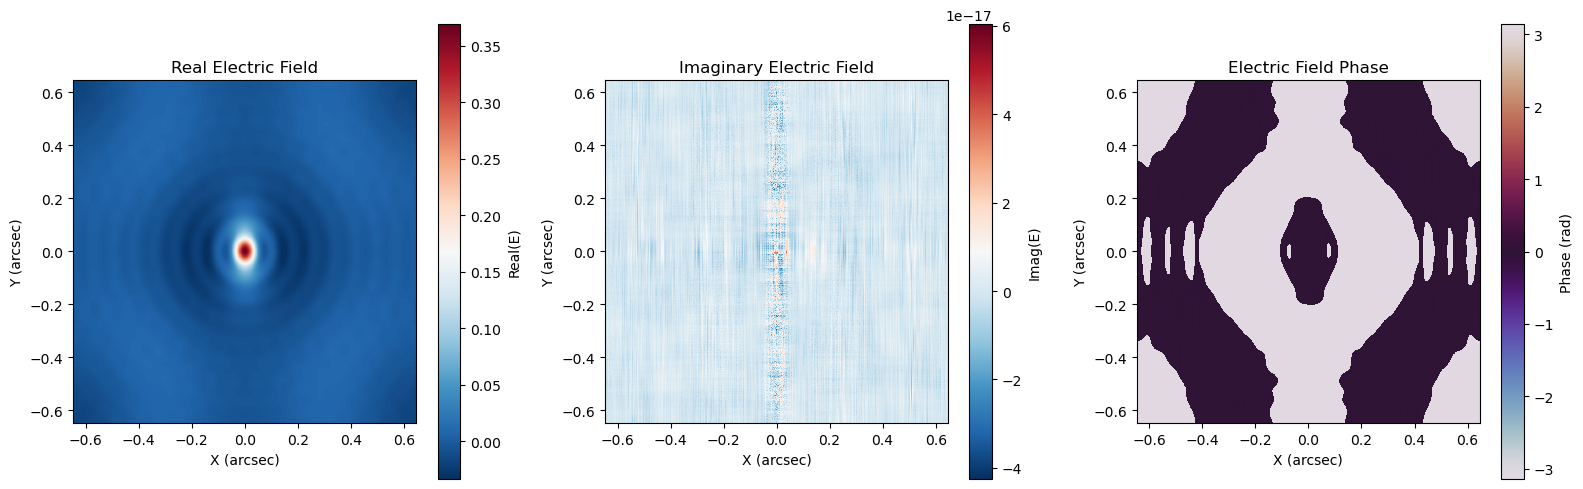

In [76]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

extent = [
    x_arcsec.min(), x_arcsec.max(),
    y_arcsec.min(), y_arcsec.max()
]

# Real component
im0 = ax[0].imshow(
    E_gal_focal.real,
    origin='lower',
    interpolation='nearest',
    cmap='RdBu_r',
    extent=extent
)
ax[0].set_title('Real Electric Field')
fig.colorbar(im0, ax=ax[0], label='Real(E)')

# Imaginary component
im1 = ax[1].imshow(
    E_gal_focal.imag,
    origin='lower',
    interpolation='nearest',
    cmap='RdBu_r',
    extent=extent
)
ax[1].set_title('Imaginary Electric Field')
fig.colorbar(im1, ax=ax[1], label='Imag(E)')

# Phase
im2 = ax[2].imshow(
    np.angle(E_gal_focal),
    origin='lower',
    interpolation='nearest',
    cmap='twilight',
    vmin=-np.pi,
    vmax=np.pi,
    extent=extent
)
ax[2].set_title('Electric Field Phase')
fig.colorbar(im2, ax=ax[2], label='Phase (rad)')

for axis in ax:
    axis.set_xlabel('X (arcsec)')
    axis.set_ylabel('Y (arcsec)')
    axis.set_aspect('equal')

plt.tight_layout()
plt.show()

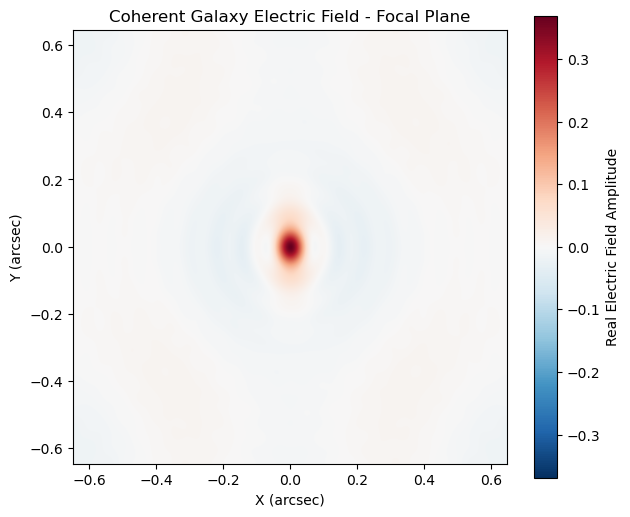

In [77]:
from matplotlib.colors import TwoSlopeNorm

E_plot = E_gal_focal.real
vmax = np.max(np.abs(E_plot))

plt.figure(figsize=(7, 6))

im = plt.imshow(
    E_plot,
    origin='lower',
    cmap='RdBu_r',
    norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
    extent=[
        x_arcsec.min(), x_arcsec.max(),
        y_arcsec.min(), y_arcsec.max()
    ]
)

plt.title('Coherent Galaxy Electric Field - Focal Plane')
plt.xlabel('X (arcsec)')
plt.ylabel('Y (arcsec)')
plt.colorbar(im, label='Real Electric Field Amplitude')
plt.show()

In [218]:
# coupling_efficiency_2d?

In [90]:
# Calculate overlap integral between the galaxy electric field and the fibre mode
overlap_intergral = coupling_efficiency_2d(E_gal_focal, E_mode_5p7micron, x_1d, y_1d)
overlap_intergral[0]

np.float64(0.6519515219622362)

In [93]:
coupling_efficiency_2d(E_gal_focal_test, E_mode_5p7micron, x_1d, y_1d)[0]

np.float64(0.8561641201739603)

In [174]:
source_sigma = 1.0 # in lambda/D units
# lambda/D = 1.5µm / 8m = 1.875e-7 rad = 0.0386 arcsec
sigma_arcsec = source_sigma * ((1.5e-6 / 8.0) * (180.0 * 3600.0 / np.pi)) # Standard deviation of the Gaussian in arcseconds
I_gaussian = np.exp(-((x_arcsec**2 + y_arcsec**2) / (2 * sigma_arcsec**2)))

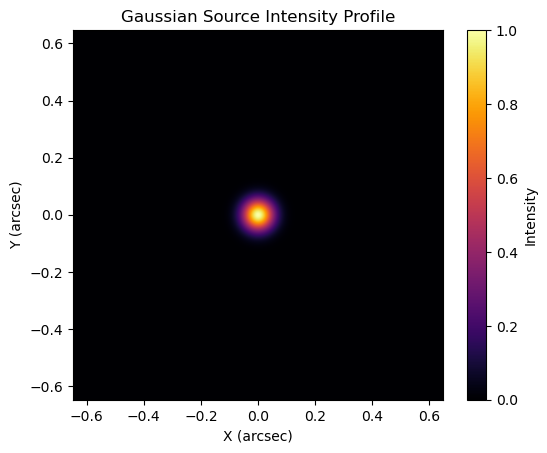

In [176]:
plt.imshow(I_gaussian, origin='lower', cmap='inferno', extent=[x_arcsec.min(), x_arcsec.max(), y_arcsec.min(), y_arcsec.max()])
# x and y axes in arcseconds
plt.xlabel('X (arcsec)')
plt.ylabel('Y (arcsec)')
plt.title('Gaussian Source Intensity Profile')
plt.colorbar(label='Intensity')
plt.show()

In [177]:
E_gaussian = np.sqrt(I_gaussian) * np.exp(1j * np.zeros_like(I_gaussian))  # Assuming a flat phase for the source
E_gaussian = E_gaussian / np.sqrt(np.sum(np.abs(E_gaussian)**2))  # Normalize the source field
E_gaussian_focal = fftconvolve(E_gaussian, E_psf, mode='same')  # Convolve the Gaussian source with the PSF to get the field at the focal plane

In [237]:
eta_gaussian_tot, mode_gaussian_res, V_array = eta_non_opt_vs_core_radius_premade(
                                                            core_radius_range, 
                                                            E_gaussian_focal, 
                                                            x, y, x_1d, y_1d,
                                                            lam0,
                                                            NA,
                                                            F_eff=F_fibre,
                                                            alpha=alpha_vlt,
                                                            decentre=None,
                                                            E_S=1.0,
                                                            mode_case="few_mode",
                                                            l_max=10,
                                                            m_max=5,
                                                            az_sym=False,
                                                            n_jobs=4,
                                                            store_mode_results=True)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    1.1s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    1.7s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    2.3s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    3.1s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    3.9s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    7.9s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   10.7s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   14.1s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:   21.6s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:   28.9s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:   39.6s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:   56.7s
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:  1.3min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  1.8min
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:  2.6min
[Parallel(

Text(0, 0.5, 'Total Coupling Efficiency')

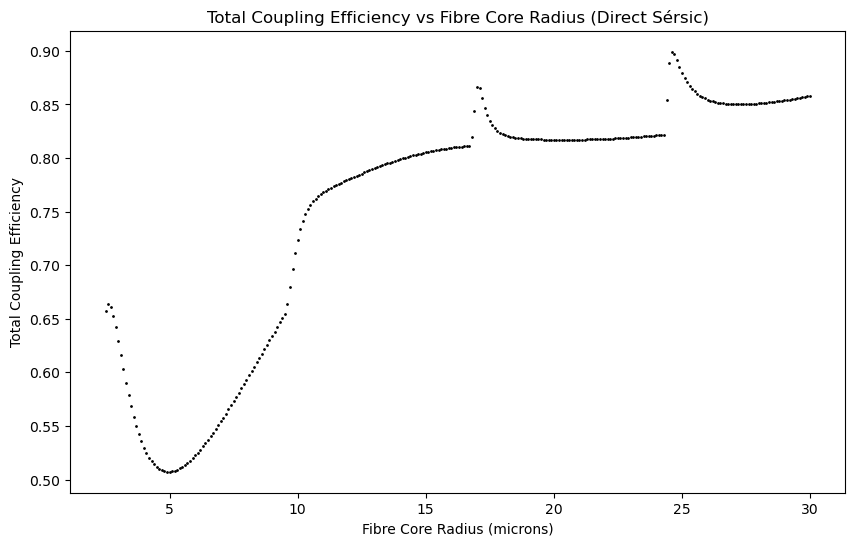

In [238]:
plt.figure(figsize=(10, 6))
plt.scatter(core_radius_range*1e6, eta_gaussian_tot, color='k', label='Total Coupling Efficiency (Direct Sérsic)', s=1)
plt.title('Total Coupling Efficiency vs Fibre Core Radius (Direct Sérsic)')
plt.xlabel('Fibre Core Radius (microns)')
plt.ylabel('Total Coupling Efficiency')

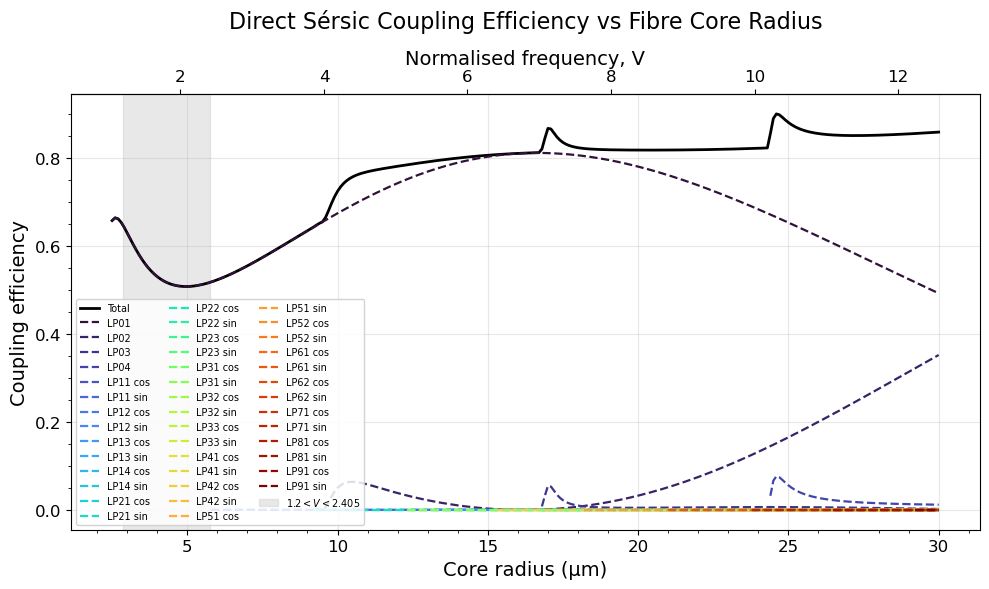

In [253]:
mode_eta, mode_lines = plot_galaxy_efficiency(
    core_radius_array=core_radius_range,
    eta_total=eta_gaussian_tot,
    results=mode_gaussian_res,
    NA=NA,
    lam0=lam0,
    title="Direct Sérsic Coupling Efficiency vs Fibre Core Radius",
    total_label="Total",
    total_color="black",
)

# Gaussian example from Ben

In [ ]:
# Arbitrary source size

source_N = 21                 # Angular source sampling
source_sigma = 1.0            # Gaussian sigma in lambda/D units
source_halfwidth = 4.0        # Half-width in lambda/D units

q = np.linspace(-source_halfwidth, source_halfwidth, source_N)

# Create a 2D grid of angular coordinates for the source
QX, QY = np.meshgrid(q, q)

In [140]:
# ============================================================
# Define the VLT base pupil electric field
# ============================================================

# Radial coordinates at the pupil plane [m]
R_pupil = np.hypot(PX, PY)

# VLT pupil mask, including central obstruction
pupil = (
    (R_pupil <= D_M1 / 2) &
    (R_pupil >= D_obstruction / 2)
)

# Diffraction-limited pupil electric field
E_base_pupil = pupil.astype(complex)

# Normalise total incident power to 1
E_base_pupil /= np.linalg.norm(E_base_pupil)

In [125]:
V

2.0943951023931957

In [129]:
# ============================================================
# 1. Calculate LP01 mode at the fibre front face
# ============================================================

l = 0
m = 1

# Calculate propagation constants
X_root, Y_root = find_root_XY(l, m, V)

# Calculate mode electric field and intensity
E_m_focal, I_m_focal = lp_mode_field_2d(
    x, y,
    a=a,
    l=l,
    X_root=X_root,
    Y_root=Y_root
)

# Normalise the mode over the full computational grid
E_m_focal = E_m_focal.astype(complex)
E_m_focal /= np.linalg.norm(E_m_focal)

I_m_focal = np.abs(E_m_focal)**2

print(f"LP{l}{m}")
print(f"X_root = {X_root:.6f}")
print(f"Y_root = {Y_root:.6f}")

LP01
X_root = 1.642167
Y_root = 1.733197


In [130]:
# ============================================================
# 2. Back-propagate LP01 to pupil plane
# ============================================================

E_m_pupil = np.fft.fftshift(
    np.fft.ifft2(
        np.fft.ifftshift(E_m_focal),
        norm='ortho'
    )
)

I_m_pupil = np.abs(E_m_pupil)**2

In [131]:
E_m_pupil.shape

(1000, 1000)

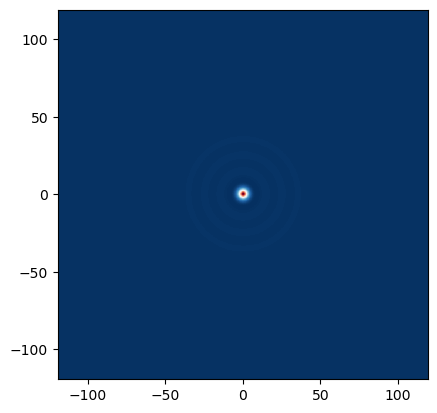

In [132]:
plt.imshow(
    E_m_pupil.real,
    origin='lower',
    interpolation='nearest',
    cmap='RdBu_r',
    extent=[
        p_1d.min(), p_1d.max(),
        p_1d.min(), p_1d.max()
    ]
)

In [ ]:
# FOurier conjugate pupil coordinates [m]

dx = x_1d[1] - x_1d[0]
N = len(x_1d)

# Effective focal length of the demagnified fibre input plane [m]
f_eff = rad_to_arcsec / plate_scale_demag

# Pupil plane coordinates in cycles per metre
p = np.fft.fftshift(np.fft.fftfreq(N, d=dx)) * lam0 * f_eff

# Define the 2D pupil coordinates using meshgrid, we need a new grid for the pupil plane,
# which is the Fourier conjugate of the focal plane. 
# The pupil coordinates are in metres, and they represent the physical size of the pupil in the telescope.
PX, PY = np.meshgrid(p, p)

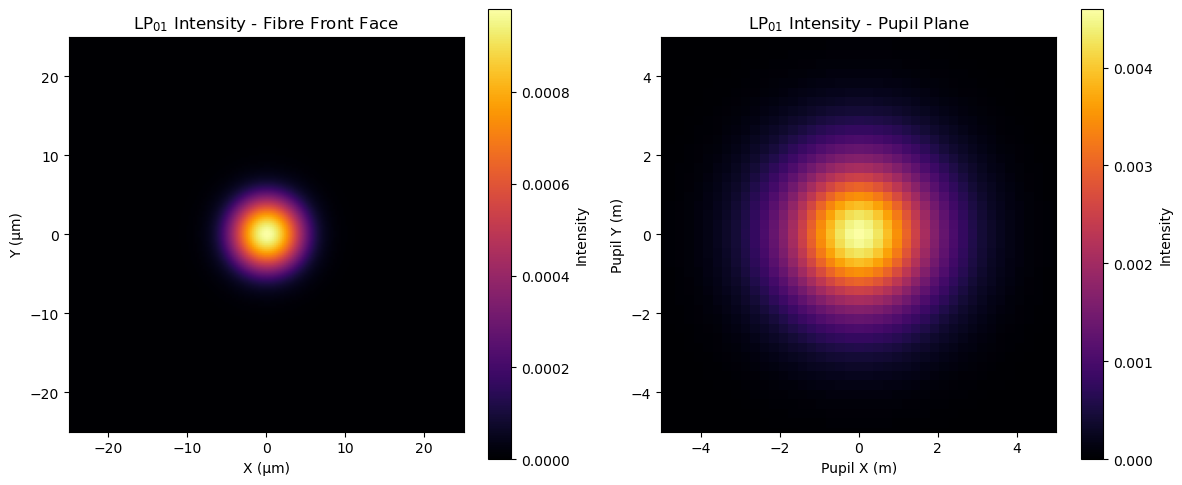

In [134]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Fibre front-face intensity
im0 = ax[0].imshow(
    I_m_focal,
    origin='lower',
    cmap='inferno',
    extent=[
        x_1d.min()*1e6, x_1d.max()*1e6,
        y_1d.min()*1e6, y_1d.max()*1e6
    ]
)
ax[0].set_title(r'LP$_{01}$ Intensity - Fibre Front Face')
ax[0].set_xlabel('X (µm)')
ax[0].set_ylabel('Y (µm)')
ax[0].set_xlim(-25, 25)
ax[0].set_ylim(-25, 25)
fig.colorbar(im0, ax=ax[0], label='Intensity')

# Back-propagated pupil intensity
im1 = ax[1].imshow(
    I_m_pupil,
    origin='lower',
    cmap='inferno',
    extent=[
        p.min(), p.max(),
        p.min(), p.max()
    ]
)
ax[1].set_title(r'LP$_{01}$ Intensity - Pupil Plane')
ax[1].set_xlabel('Pupil X (m)')
ax[1].set_ylabel('Pupil Y (m)')
ax[1].set_xlim(-5, 5)
ax[1].set_ylim(-5, 5)
fig.colorbar(im1, ax=ax[1], label='Intensity')

plt.tight_layout()
plt.show()

In [219]:
# np.vdot?

In [135]:
P_mode_focal = np.vdot(E_m_focal, E_m_focal).real
P_mode_pupil = np.vdot(E_m_pupil, E_m_pupil).real

print(f"LP01 power at fibre front: {P_mode_focal:.8f}")
print(f"LP01 power at pupil:       {P_mode_pupil:.8f}")

LP01 power at fibre front: 1.00000000
LP01 power at pupil:       1.00000000


In [139]:
source_N

21

## Gaussian Extended Source - Fibre coupling efficiency at pupil plane

In [141]:
# ============================================================
# Gaussian surface brightness profile
# ============================================================

I_source_sky = np.exp(
    -(QX**2 + QY**2) / (2 * source_sigma**2)
)

# Normalise source intensity to total flux = 1
I_source_sky /= np.sum(I_source_sky)

# ============================================================
# Store results
# ============================================================

source_coupling = np.zeros_like(I_source_sky)

incoherent_modal_power = np.zeros_like(I_source_sky)

coherent_amplitude = 0.0j

E_source_pupil = np.zeros_like(E_base_pupil, dtype=complex)

# ============================================================
# Calculate Gaussian source coupling
# ============================================================

for iy in range(source_N):
    for ix in range(source_N):

        # Angular phase tilt (QX and QY in lambda/D units)
        tilt = np.exp(
            2j * np.pi *
            (QX[iy, ix] * PX + QY[iy, ix] * PY) / D_M1
        )

        # Point-source pupil electric field
        E_psf_pupil = E_base_pupil * tilt

        # Overlap with back-propagated fibre mode
        amplitude = np.vdot(E_m_pupil, E_psf_pupil)

        # Point-source modal coupling efficiency
        powers = np.abs(amplitude)**2

        # Coherent source amplitude weight
        weight = np.sqrt(I_source_sky[iy, ix])

        # Add coherent amplitudes
        coherent_amplitude += amplitude * weight

        # Add coherent pupil fields
        E_source_pupil += E_psf_pupil * weight

        # Store point-source coupling
        source_coupling[iy, ix] = powers

        # Incoherent extended source: add weighted powers
        incoherent_modal_power[iy, ix] = (
            powers * I_source_sky[iy, ix]
        )

# ============================================================
# Total coupling efficiencies
# ============================================================

# Incoherent coupling: sum weighted powers
eta_incoherent = np.sum(incoherent_modal_power)

# Coherent source power at pupil
P_coherent_pupil = np.vdot(
    E_source_pupil, E_source_pupil
).real

# Coherent coupling: sum amplitudes before squaring
eta_coherent = (
    np.abs(coherent_amplitude)**2 / P_coherent_pupil
)

print(f"Incoherent Gaussian coupling: {eta_incoherent:.6f}")
print(f"Coherent Gaussian coupling:   {eta_coherent:.6f}")
print(f"Coherent / incoherent ratio:  {eta_coherent / eta_incoherent:.4f}")

Incoherent Gaussian coupling: 0.143025
Coherent Gaussian coupling:   0.502936
Coherent / incoherent ratio:  3.5164


In [142]:
overlap = np.vdot(E_m_pupil, E_source_pupil)

P_source = np.vdot(E_source_pupil, E_source_pupil).real
P_mode = np.vdot(E_m_pupil, E_m_pupil).real

eta_LP01 = np.abs(overlap)**2 / (P_source * P_mode)

print(f"LP01 coupling efficiency: {eta_LP01:.6f}")

LP01 coupling efficiency: 0.502936


## Galaxy

In [ ]:
# Sérsic extended source - surface brightness distribution

# QX and QY are angular coordinates in lambda/D units.
# The Sérsic model expects angular coordinates in arcseconds.
#
# Convert lambda/D into radians, then into arcseconds.

lambda_D_arcsec = (lam0 / D_M1) * rad_to_arcsec

QX_arcsec = QX * lambda_D_arcsec
QY_arcsec = QY * lambda_D_arcsec

# Evaluate the Sérsic profile at each angular source position.
#
# model_cent is the Sersic2D model previously defined using:
# n_sersic, Re_arcsec, ellip, and PA_deg.
#
# The result represents the surface brightness distribution
# of the extended galaxy on the sky.

I_source_sky = model_cent(QX_arcsec, QY_arcsec)

# Normalise the source intensity so that the total
# fractional flux across the sampled source grid equals 1.
#
# Each pixel now contributes a fraction of the total
# sampled galaxy flux.

I_source_sky /= np.sum(I_source_sky)

In [ ]:
# Store results

# Point-source coupling efficiency at each angular position
source_coupling = np.zeros_like(I_source_sky)

# Brightness-weighted modal power at each angular position
# for an incoherent extended source
incoherent_modal_power = np.zeros_like(I_source_sky)

# Complex coupling amplitude accumulated over all source positions
# for a fully coherent extended source
coherent_amplitude = 0.0j

# Total coherent electric field of the Sérsic galaxy
# at the VLT pupil plane
E_source_pupil = np.zeros_like(E_base_pupil, dtype=complex)


# Calculate Sérsic extended-source coupling at the pupil plane

for iy in range(source_N):
    for ix in range(source_N):

        # 1. Angular phase tilt

        # Each galaxy element occupies a different angular position
        # on the sky, producing a different phase gradient across
        # the telescope pupil.
        #
        # QX, QY are in lambda/D units.
        # PX, PY are physical pupil coordinates [m].
        #
        # The tilt is independent of whether the source brightness
        # follows a Gaussian or Sérsic distribution.

        tilt = np.exp(
            2j * np.pi *
            (QX[iy, ix] * PX + QY[iy, ix] * PY) / D_M1
        )

        # 2. Point-source electric field at the pupil

        E_psf_pupil = E_base_pupil * tilt

        # 3. Overlap with the back-propagated fibre mode

        # Calculate the complex modal coupling amplitude
        # for the point source at this angular position.

        amplitude = np.vdot(E_m_pupil, E_psf_pupil)

        # Point-source modal coupling efficiency
        # assuming both fields have unit power.

        powers = np.abs(amplitude)**2

        # 4. Coherent amplitude weight

        # The Sérsic profile represents intensity.
        # Electric-field amplitude is proportional to sqrt(intensity).
        #
        # We assume zero intrinsic phase difference between
        # all galaxy elements.

        weight = np.sqrt(I_source_sky[iy, ix])

        # Coherent source: accumulate complex modal amplitudes
        coherent_amplitude += amplitude * weight

        # Coherent source: accumulate complex pupil fields
        E_source_pupil += E_psf_pupil * weight

        # Store point-source coupling at each angular position
        source_coupling[iy, ix] = powers

        # 5. Incoherent extended-source coupling

        # Each angular position contributes independently.
        # Add brightness-weighted modal powers, not amplitudes.

        incoherent_modal_power[iy, ix] = (
            powers * I_source_sky[iy, ix]
        )


# Total coupling efficiencies

# Incoherent source: sum the weighted modal powers
eta_incoherent_sersic = np.sum(incoherent_modal_power)

# Coherent source: calculate actual total pupil power
P_coherent_pupil = np.vdot(
    E_source_pupil, E_source_pupil
).real

# Coherent source: square the summed complex amplitudes
# and normalise by the actual total coherent pupil power
eta_coherent_sersic = (
    np.abs(coherent_amplitude)**2 / P_coherent_pupil
)

print(f"Incoherent Sérsic coupling: {eta_incoherent_sersic:.6f}")
print(f"Coherent Sérsic coupling:   {eta_coherent_sersic:.6f}")
print(
    f"Coherent / incoherent ratio: "
    f"{eta_coherent_sersic / eta_incoherent_sersic:.4f}"
)

Incoherent Sérsic coupling: 0.516632
Coherent Sérsic coupling:   0.714209
Coherent / incoherent ratio: 1.3824


In [ ]:
def prepare_gaussian_source_pupil(
    E_base_pupil,
    PX, PY,
    D_M1,
    source_N=21,
    source_sigma=1.0,
    source_halfwidth=4.0
):
    """
    Precompute the point-source pupil fields for a Gaussian
    extended source.

    The source is represented as discrete point-source elements
    at angular positions expressed in lambda/D units.

    For each source element, construct the tilted telescope
    pupil electric field.

    These fields are independent of the fibre core radius,
    so they only need to be calculated once.

    Parameters
    ----------
    E_base_pupil : 2D complex array
        Normalised electric field of an on-axis point source
        across the telescope pupil.

    PX, PY : 2D arrays
        Telescope pupil coordinates [m].

    D_M1 : float
        Telescope primary mirror diameter [m].

    source_N : int
        Number of angular source samples along each axis.

    source_sigma : float
        Gaussian standard deviation in lambda/D units.

    source_halfwidth : float
        Half-width of the angular source grid in lambda/D units.

    Returns
    -------
    source_data : dict
        Contains the Gaussian brightness, source coordinates,
        precomputed point-source pupil fields, and coherent
        source field.
    """

    # ========================================================
    # 1. Gaussian surface brightness distribution on the sky
    # ========================================================

    q = np.linspace(
        -source_halfwidth,
        source_halfwidth,
        source_N
    )

    QX, QY = np.meshgrid(q, q)

    # Circularly symmetric 2D Gaussian brightness profile.
    I_source_sky = np.exp(
        -(QX**2 + QY**2) / (2 * source_sigma**2)
    )

    # Normalise total fractional source flux to 1.
    I_source_sky /= np.sum(I_source_sky)


    # ========================================================
    # 2. Extract nonzero telescope pupil pixels
    # ========================================================

    # There is no incident electric field outside the telescope
    # aperture, so those pixels do not contribute to the overlap.
    #
    # We only store the nonzero pupil pixels to reduce memory
    # requirements during the fibre core-radius sweep.

    pupil_indices = np.flatnonzero(
        np.abs(E_base_pupil.ravel()) > 0
    )

    PX_active = PX.ravel()[pupil_indices]
    PY_active = PY.ravel()[pupil_indices]

    E_base_active = E_base_pupil.ravel()[pupil_indices]

    # Normalise the on-axis pupil electric field.
    # This ensures that each tilted point-source pupil field
    # has unit total discrete power.

    E_base_active = (
        E_base_active / np.linalg.norm(E_base_active)
    )


    # ========================================================
    # 3. Construct the angular phase tilts
    # ========================================================

    # Flatten the source grid so that each row corresponds
    # to one angular source position.
    #
    # QX_flat, QY_flat: (source_N**2,)
    # PX_active, PY_active: (number of pupil pixels,)
    #
    # The result has shape:
    #
    # (number of source positions, number of pupil pixels)

    QX_flat = QX.ravel()
    QY_flat = QY.ravel()

    tilt = np.exp(
        2j * np.pi / D_M1 * (
            QX_flat[:, None] * PX_active[None, :] +
            QY_flat[:, None] * PY_active[None, :]
        )
    )

    # Each row contains the point-source pupil electric
    # field for one angular position on the sky.

    E_point_pupil = tilt * E_base_active[None, :]


    # ========================================================
    # 4. Construct coherent Gaussian pupil field
    # ========================================================

    # For the hypothetical fully coherent source, we assume
    # zero relative intrinsic phase between source elements.
    #
    # Therefore, each complex pupil field is weighted by
    # the square root of its fractional source intensity.

    coherent_weights = np.sqrt(I_source_sky.ravel())

    # Coherently sum all point-source pupil electric fields.
    #
    # This is equivalent to:
    #
    # E_source_pupil += sqrt(I_source_sky[iy, ix]) *
    #                   E_point_pupil[iy, ix]
    #
    # but uses matrix multiplication instead of a Python loop.

    E_source_pupil_active = (
        coherent_weights @ E_point_pupil
    )


    # ========================================================
    # 5. Calculate actual coherent pupil power
    # ========================================================

    # Coherent electric fields interfere, so the total power
    # of their sum is not generally equal to the sum of
    # their individual powers.

    P_coherent_pupil = np.vdot(
        E_source_pupil_active,
        E_source_pupil_active
    ).real


    # ========================================================
    # 6. Store source data
    # ========================================================

    source_data = {
        "QX": QX,
        "QY": QY,
        "I_source_sky": I_source_sky,
        "pupil_indices": pupil_indices,
        "E_point_pupil": E_point_pupil,
        "E_source_pupil_active": E_source_pupil_active,
        "P_coherent_pupil": P_coherent_pupil
    }

    return source_data

In [146]:
def total_eff_pupil_2d_premade(
    prepared_modes,
    source_data,
    store_mode_results=True
):
    """
    Calculate total coherent and incoherent Gaussian extended-source
    coupling efficiencies for one fibre core radius.

    Fibre mode fields are generated at the fibre front face,
    then Fourier-transformed back to the telescope pupil.

    The overlap is calculated directly in the pupil plane.

    Parameters
    ----------
    prepared_modes : list of dict
        Precomputed fibre modes from prepare_modes_2d().
        Each dictionary contains an E_mode field defined on
        the fibre front-face grid.

    source_data : dict
        Precomputed Gaussian pupil fields generated by
        prepare_gaussian_source_pupil().

    store_mode_results : bool
        Whether to store individual modal coupling efficiencies.

    Returns
    -------
    eta_incoherent_total : float
        Total incoherent extended-source coupling efficiency.

    eta_coherent_total : float
        Total coherent extended-source coupling efficiency.

    mode_results : list or None
        Per-mode coupling results.
    """

    # ========================================================
    # 1. Extract precomputed Gaussian source data
    # ========================================================

    I_source_sky = source_data["I_source_sky"]

    pupil_indices = source_data["pupil_indices"]

    E_point_pupil = source_data["E_point_pupil"]

    E_source_pupil_active = (
        source_data["E_source_pupil_active"]
    )

    P_coherent_pupil = source_data["P_coherent_pupil"]

    # Each source element contributes a fractional flux
    # defined by the Gaussian brightness distribution.

    brightness_flat = I_source_sky.ravel()


    # ========================================================
    # 2. Initialise coupling efficiencies
    # ========================================================

    eta_incoherent_total = 0.0
    eta_coherent_total = 0.0

    mode_results = [] if store_mode_results else None


    # ========================================================
    # 3. Loop through all supported fibre modes
    # ========================================================

    for mode in prepared_modes:

        # ----------------------------------------------------
        # 3.1. Extract the fibre mode at the focal plane
        # ----------------------------------------------------

        E_m_focal = np.asarray(
            mode["E_mode"],
            dtype=complex
        )

        # Normalise the fibre mode over the entire
        # computational grid, including the cladding tail.

        E_m_focal /= np.linalg.norm(E_m_focal)


        # ----------------------------------------------------
        # 3.2. Back-propagate fibre mode to pupil plane
        # ----------------------------------------------------

        # We use ifft2 because our forward pupil-to-focal
        # propagation convention uses fft2.
        #
        # The unitary FFT preserves inner products, allowing
        # us to calculate coupling at either optical plane.

        E_m_pupil = np.fft.fftshift(
            np.fft.ifft2(
                np.fft.ifftshift(E_m_focal),
                norm="ortho"
            )
        )


        # ----------------------------------------------------
        # 3.3. Extract mode field within telescope pupil
        # ----------------------------------------------------

        # The point-source pupil electric fields are zero
        # outside the telescope aperture.
        #
        # We therefore only need the back-propagated mode
        # values at those positions when calculating overlaps.
        #
        # IMPORTANT:
        # We do not renormalise the cropped mode field.
        # The mode remains normalised over the complete
        # back-propagated pupil grid.

        E_m_pupil_active = (
            E_m_pupil.ravel()[pupil_indices]
        )


        # ----------------------------------------------------
        # 3.4. Point-source modal coupling amplitudes
        # ----------------------------------------------------

        # Each row of E_point_pupil represents one point source
        # at a different angular position.
        #
        # For each point source:
        #
        # amplitude = sum(conj(E_m_pupil) * E_point_pupil)
        #
        # Matrix multiplication evaluates the same overlap
        # for all angular positions simultaneously.

        amplitudes = (
            E_point_pupil @ np.conj(E_m_pupil_active)
        )

        # Point-source modal coupling efficiencies.

        powers = np.abs(amplitudes)**2


        # ----------------------------------------------------
        # 3.5. Incoherent Gaussian coupling
        # ----------------------------------------------------

        # For incoherent illumination, the complex fields from
        # different angular positions are uncorrelated.
        #
        # Their modal powers are therefore added with weights
        # given by the fractional Gaussian brightness.

        eta_incoherent_mode = np.sum(
            brightness_flat * powers
        )


        # ----------------------------------------------------
        # 3.6. Coherent Gaussian coupling
        # ----------------------------------------------------

        # For coherent illumination, we first calculate
        # the complex overlap with the total coherent
        # source pupil electric field.
        #
        # This is equivalent to summing all weighted complex
        # modal amplitudes before taking the squared magnitude.

        coherent_amplitude = np.vdot(
            E_m_pupil_active,
            E_source_pupil_active
        )

        # Normalise by the actual coherent source pupil power.

        eta_coherent_mode = (
            np.abs(coherent_amplitude)**2
            / P_coherent_pupil
        )


        # ----------------------------------------------------
        # 3.7. Accumulate efficiencies across fibre modes
        # ----------------------------------------------------

        eta_incoherent_total += eta_incoherent_mode

        eta_coherent_total += eta_coherent_mode


        # ----------------------------------------------------
        # 3.8. Store individual modal results
        # ----------------------------------------------------

        if store_mode_results:

            mode_results.append({
                "l": mode["l"],
                "m": mode["m"],
                "cutoff_V": mode["cutoff_V"],
                "X_root": mode["X_root"],
                "Y_root": mode["Y_root"],
                "angular": mode["angular"],
                "eta_incoherent": eta_incoherent_mode,
                "eta_coherent": eta_coherent_mode
            })

    return (
        eta_incoherent_total,
        eta_coherent_total,
        mode_results
    )

In [150]:
from joblib import Parallel, delayed

def eta_gaussian_vs_core_radius_pupil(
    core_radius_array,
    source_data,
    x, y,
    lam0,
    NA,
    mode_case="few_mode",
    l_max=10,
    m_max=5,
    az_sym=False,
    n_jobs=1,
    store_mode_results=True
):
    """
    Calculate coherent and incoherent Gaussian source coupling
    efficiency as a function of fibre core radius.

    The telescope pupil and Gaussian source fields remain fixed.
    Only the fibre core radius and its supported modes change.

    Parameters
    ----------
    core_radius_array : array
        Fibre core radius values [m].

    source_data : dict
        Precomputed Gaussian source pupil fields from
        prepare_gaussian_source_pupil().

    x, y : 2D arrays
        Physical coordinate grids at the fibre front face [m].

    lam0 : float
        Observing wavelength [m].

    NA : float
        Fibre numerical aperture.

    mode_case : str
        Fibre mode case, e.g. "smf" or "few_mode".

    l_max, m_max : int
        Maximum azimuthal and radial mode orders.

    az_sym : bool
        If True, only include azimuthally symmetric modes (l=0).
        If False, include all supported modes.

    n_jobs : int
        Number of parallel workers.
        n_jobs=1 uses serial execution.
        n_jobs>1 uses parallel execution.

    store_mode_results : bool
        If True, store individual mode coupling efficiencies
        for each fibre core radius.
        If False, only store total coupling efficiencies.

    Returns
    -------
    eta_incoherent_array : 1D numpy array
        Total incoherent Gaussian coupling versus core radius.

    eta_coherent_array : 1D numpy array
        Total coherent Gaussian coupling versus core radius.

    mode_results_array : list or None
        Per-mode coupling results for each core radius.

    V_array : 1D numpy array
        Fibre normalised frequency versus core radius.
    """

    core_radius_array = np.asarray(core_radius_array)

    # Calculate the normalised frequency (V-number)
    # corresponding to each fibre core radius.
    V_array = (
        2 * np.pi * core_radius_array * NA / lam0
    )

    n_total = len(core_radius_array)

    # ========================================================
    # 1. Define calculation for one fibre core radius
    # ========================================================

    # Each core radius can be calculated independently.
    #
    # We therefore define a function that calculates the
    # supported fibre modes and their pupil-plane coupling
    # efficiencies for one particular radius.
    #
    # This function can be executed either serially
    # or by a parallel worker.

    def run_one_radius(a):

        # Calculate all guided fibre modes supported by
        # this core radius and numerical aperture.
        #
        # These modes are defined at the fibre front face
        # on the same physical x, y coordinate grid.

        prepared_modes = prepare_modes_2d(
            x, y,
            a=a,
            NA=NA,
            lam0=lam0,
            az_sym=az_sym,
            mode_case=mode_case,
            l_max=l_max,
            m_max=m_max
        )

        # Calculate the coherent and incoherent coupling
        # efficiencies at the telescope pupil plane.
        #
        # Each fibre mode is back-propagated to the pupil,
        # and its overlap with the Gaussian source pupil
        # fields is evaluated.

        eta_inc, eta_coh, mode_results = (
            total_eff_pupil_2d_premade(
                prepared_modes=prepared_modes,
                source_data=source_data,
                store_mode_results=store_mode_results
            )
        )

        # Return results for this particular core radius.
        return eta_inc, eta_coh, mode_results


    # ========================================================
    # 2. Serial execution
    # ========================================================

    if n_jobs == 1:

        eta_incoherent_array = []
        eta_coherent_array = []

        mode_results_array = [] if store_mode_results else None

        # Progress checkpoints every 10%
        checkpoints = {
            max(1, int(np.ceil(n_total * p / 10)))
            for p in range(1, 11)
        }

        # Loop through fibre core radii one at a time.

        for i, a in enumerate(core_radius_array, start=1):

            eta_inc, eta_coh, mode_results = run_one_radius(a)

            # Store total coupling efficiencies.
            eta_incoherent_array.append(eta_inc)
            eta_coherent_array.append(eta_coh)

            # Optionally store individual fibre mode results.
            if store_mode_results:
                mode_results_array.append(mode_results)

            # Print progress at approximately every 10%.
            if i in checkpoints:
                percent = int(round(100 * i / n_total))

                print(
                    f"{percent}% complete "
                    f"({i}/{n_total}), "
                    f"core radius = {a*1e6:.2f} µm"
                )


    # ========================================================
    # 3. Parallel execution
    # ========================================================

    else:

        # Each worker independently calculates the supported
        # fibre modes and coupling efficiencies for one radius.
        #
        # n_jobs controls the maximum number of concurrent workers.
        #
        # verbose=10 prints joblib progress information.

        results = Parallel(
            n_jobs=n_jobs,
            verbose=10,
            backend="threading"
        )(
            delayed(run_one_radius)(a)
            for a in core_radius_array
        )

        # Parallel returns a list of tuples:
        #
        # [
        #     (eta_inc_1, eta_coh_1, mode_results_1),
        #     (eta_inc_2, eta_coh_2, mode_results_2),
        #     ...
        # ]
        #
        # Extract each output into its corresponding array.

        eta_incoherent_array = [
            row[0] for row in results
        ]

        eta_coherent_array = [
            row[1] for row in results
        ]

        if store_mode_results:
            mode_results_array = [
                row[2] for row in results
            ]
        else:
            mode_results_array = None


    # ========================================================
    # 4. Convert coupling results to numpy arrays
    # ========================================================

    eta_incoherent_array = np.asarray(
        eta_incoherent_array
    )

    eta_coherent_array = np.asarray(
        eta_coherent_array
    )


    # ========================================================
    # 5. Return results
    # ========================================================

    return (
        eta_incoherent_array,
        eta_coherent_array,
        mode_results_array,
        V_array
    )

In [148]:
# ============================================================
# Prepare Gaussian source
# ============================================================

gaussian_source_data = prepare_gaussian_source_pupil(
    E_base_pupil=E_base_pupil,
    PX=PX,
    PY=PY,
    D_M1=D_M1,
    source_N=21,
    source_sigma=1.0,
    source_halfwidth=4.0
)

In [152]:
(
    eta_gaussian_incoherent,
    eta_gaussian_coherent,
    mode_results_gaussian,
    V_array
) = eta_gaussian_vs_core_radius_pupil(
    core_radius_array=core_radius_range,
    source_data=gaussian_source_data,
    x=x,
    y=y,
    lam0=lam0,
    NA=NA,
    mode_case="few_mode",
    az_sym=False,
    n_jobs=4,
    store_mode_results=True
)

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    1.1s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    1.8s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    2.8s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    3.7s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    5.0s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    9.1s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   11.7s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   14.9s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:   24.4s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:   32.6s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:   45.2s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:  1.0min
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:  1.4min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  1.8min
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:  2.5min
[Para

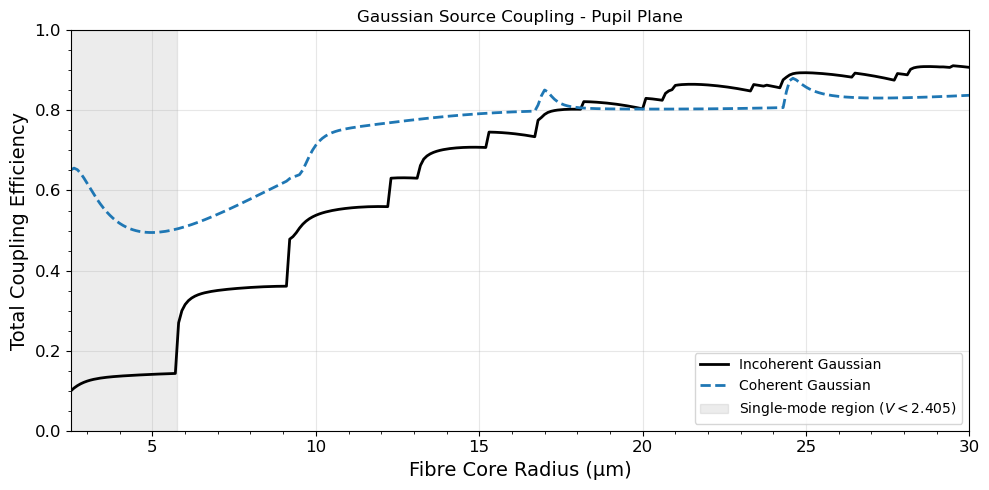

In [204]:
plt.figure(figsize=(10, 5))

plt.plot(
    core_radius_range * 1e6,
    eta_gaussian_incoherent,
    label="Incoherent Gaussian",
    color="black",
    linewidth=2
)

plt.plot(
    core_radius_range * 1e6,
    eta_gaussian_coherent,
    label="Coherent Gaussian",
    color="tab:blue",
    linestyle="--",
    linewidth=2
)

# Shade the single-mode region
plt.axvspan(
    0,
    a_max_single * 1e6,
    color="grey",
    alpha=0.15,
    label=r"Single-mode region ($V<2.405$)"
)

plt.xlabel("Fibre Core Radius (µm)", fontsize=14)
plt.ylabel("Total Coupling Efficiency", fontsize=14)
plt.title("Gaussian Source Coupling - Pupil Plane")

plt.tick_params(axis="both", labelsize=12)
plt.minorticks_on()
plt.grid(True, alpha=0.3)
plt.legend()

plt.ylim(0, 1)
plt.xlim(core_radius_range[0]*1e6, core_radius_range[-1]*1e6)

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Total Coupling Efficiency')

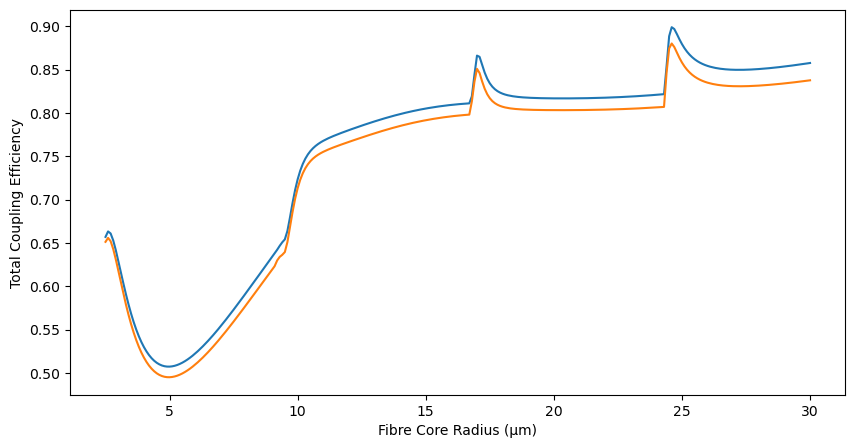

In [226]:
plt.figure(figsize=(10, 5))
plt.plot(core_radius_range * 1e6, eta_gaussian_tot)
plt.plot(core_radius_range * 1e6, eta_gaussian_coherent)
plt.xlabel("Fibre Core Radius (µm)")
plt.ylabel("Total Coupling Efficiency")

In [ ]:
def prepare_sersic_source_pupil(
        E_base_pupil, 
        PX, PY,
        D_M1, lam0, 
        sersic_model, 
        source_N=21, 
        source_halfwidth=4.0, 
        pixel_subsamples=1
): 
        """
        Precompute the point-source pupil fields for a Sérsic extended source.
        
        The sersic galaxy is represented as a collection of discrete point-source elements distributed 
        across the sky. 

        For each source element, construct the telescope pupil field with the appropriate angular phase tilt. 

        The pupi fields are indpendent of fibre core radius, so they only need to be calculated once.

        Parameters
        ----------
        E_base_pupil : 2D complex array
            Normalised electric field of an on-axis point source across the telescope pupil.
        PX, PY : 2D arrays
            Physical telescope pupil coordinates [m].
        D_M1 : float
                Telescope primary mirror diameter [m].

        lam0 : float
                Observing wavelength [m].

        sersic_model : astropy.modeling.models.Sersic2D
                Sérsic surface brightness model, evaluated in arcsec.

        source_N : int
                Number of angular source samples along each axis.
        source_halfwidth : float
                Half-width of the angular source grid in the lambda/D units. 
        
        pixel_subsamples : int
                Number of subpixels along each axis used to estimate
                the integrated flux in each angular source pixel.
                1 uses the Sérsic brightness at the pixel centre.
                Values greater than 1 improve sampling of the central peak.

        Returns
        -------
        source_data : dict
                Precomputed Sersic source data containing: 
                - QX, QY: angular coordinates in lambda/D units
                - QX_arcsec, QY_arcsec: angular coordinates in arcseconds
                - I_source_sky: Normalised Sérsic surface brightness distribution
                - pupil_indices: non zero telescope pupil pixels
                - E_point_pupil: individual point-source pupil fields for each angular position
                - E_source_pupil_active: total coherent source pupil field
                - P_coherent_pupil: total coherent incident power
        """

        # 1. Define angular source ooorinate grid

        # In the Gaussian calcualtion, angular positions are intially expressed in lambda/D units. 
        # These coordinates are used when calculating the geometrical phase tilts across the telescope pupil. 

        q = np.linspace(
                -source_halfwidth, 
                source_halfwidth, 
                source_N
        )

        QX, QY = np.meshgrid(q,q)

        # 2. Convert angualr position into arcseconds

        # The Sersic2D model was defined using angular radii in arcseconds. 

        # One lambda/D corresponds to: theta = lam0 / D_M1 in radians.

        # COnvert radians to arcseconds

        rad_to_arcsec = 180.0 * 3600.0 / np.pi

        lambda_D_arcsec = (lam0 / D_M1) * rad_to_arcsec

        # Convert the angular coordinates from lambda/D units into arcseconds
        QX_arcsec = QX * lambda_D_arcsec
        QY_arcsec = QY * lambda_D_arcsec

        # 3. Calcualte the Sersic surface brightness distribution

        # We can evaluate teh brightness at each angular grid position or estimate teh clux over each sourec pixel
        if pixel_subsamples == 1: 

                # Use the brightness at each angualar source position. 
                I_source_sky = sersic_model(QX_arcsec, QY_arcsec)

        else:

                # Approximate the integrated flux within each angular
                # source pixel by evaluating the Sérsic profile at
                # regularly spaced subpixel positions.
                #
                # This reduces sensitivity to the very bright central
                # pixel of a high-n Sérsic profile.

                dq_arcsec = (
                q[1] - q[0]
                ) * lambda_D_arcsec

                offsets = (
                (np.arange(pixel_subsamples) + 0.5)
                / pixel_subsamples - 0.5
                ) * dq_arcsec

                I_source_sky = np.zeros_like(QX_arcsec)

                for offset_y in offsets:
                        for offset_x in offsets:

                                I_source_sky = sersic_model(
                                QX_arcsec + offset_x,
                                QY_arcsec + offset_y
                                )

                        # Average surface brightness across the subpixels.
                        # Since all source pixels have equal area, this is
                        # proportional to their integrated flux.

                        I_source_sky /= pixel_subsamples**2


        # ========================================================
        # 4. Normalise the Sérsic source brightness
        # ========================================================

        # Each angular source pixel contributes a fraction of
        # the galaxy flux within the sampled angular region.
        #
        # The sum of these fractional contributions equals 1.
        #
        # Note that this normalisation refers to the sampled
        # angular region, not necessarily the entire galaxy.

        I_source_sky /= np.sum(I_source_sky)


        # ========================================================
        # 5. Extract nonzero telescope pupil pixels
        # ========================================================

        # The telescope pupil field is zero outside the aperture.
        #
        # We therefore only store point-source electric fields
        # over the nonzero pupil pixels to reduce memory usage.

        pupil_indices = np.flatnonzero(
                np.abs(E_base_pupil.ravel()) > 0
        )

        PX_active = PX.ravel()[pupil_indices]
        PY_active = PY.ravel()[pupil_indices]

        E_base_active = (
                E_base_pupil.ravel()[pupil_indices]
        )

        # Normalise on-axis point-source pupil field to unit power.
        #
        # Every tilted point-source field will consequently also
        # have unit power, because the phase tilt has magnitude 1.

        E_base_active = (
                E_base_active / np.linalg.norm(E_base_active)
        )


        # ========================================================
        # 6. Construct point-source pupil electric fields
        # ========================================================

        # Each angular position contributes a different
        # geometrical phase tilt:
        #
        # tilt = exp[2*pi*i*(qx*PX + qy*PY)/D]
        #
        # This expression is independent of the source brightness
        # model. It is exactly the same tilt used for the Gaussian.

        QX_flat = QX.ravel()
        QY_flat = QY.ravel()

        tilt = np.exp(
                2j * np.pi / D_M1 * (
                QX_flat[:, None] * PX_active[None, :] +
                QY_flat[:, None] * PY_active[None, :]
                )
        )

        # Each row represents the complex pupil electric field
        # from one angular source element.

        E_point_pupil = (
                tilt * E_base_active[None, :]
        )


        # ========================================================
        # 7. Construct the coherent Sérsic pupil electric field
        # ========================================================

        # Assume all source elements have zero relative
        # intrinsic phase.
        #
        # The electric-field amplitude contributed by a source
        # element is proportional to sqrt(intensity).
        #
        # The geometrical pupil tilts still contain spatial
        # phase variations, even with zero intrinsic source phase.

        coherent_weights = np.sqrt(
                I_source_sky.ravel()
        )

        # Add the weighted complex pupil fields.
        #
        # This preserves interference between source positions.

        E_source_pupil_active = (
                coherent_weights @ E_point_pupil
        )


        # ========================================================
        # 8. Calculate total coherent incident pupil power
        # ========================================================

        # Unlike incoherent illumination, the total power of
        # the coherently summed electric field is not necessarily
        # equal to the sum of the individual source powers.

        P_coherent_pupil = np.vdot(
                E_source_pupil_active,
                E_source_pupil_active
        ).real


        # ========================================================
        # 9. Store all precomputed source data
        # ========================================================

        source_data = {
                "QX": QX,
                "QY": QY,
                "QX_arcsec": QX_arcsec,
                "QY_arcsec": QY_arcsec,
                "I_source_sky": I_source_sky,
                "pupil_indices": pupil_indices,
                "E_point_pupil": E_point_pupil,
                "E_source_pupil_active": E_source_pupil_active,
                "P_coherent_pupil": P_coherent_pupil
        }

        return source_data 

In [ ]:
def eta_sersic_vs_core_radius_pupil(
    core_radius_array,
    source_data,
    x, y,
    lam0,
    NA,
    mode_case="few_mode",
    l_max=10,
    m_max=5,
    az_sym=False,
    n_jobs=1,
    store_mode_results=True
):
    """
    Calculate coherent and incoherent Sérsic galaxy coupling
    efficiency as a function of fibre core radius.

    The Sérsic source brightness distribution and telescope
    pupil remain fixed for every fibre core radius.

    Only the fibre radius and its supported guided modes change.

    Parameters
    ----------
    core_radius_array : array
        Fibre core radius values [m].

    source_data : dict
        Precomputed Sérsic source pupil fields from
        prepare_sersic_source_pupil().

    x, y : 2D arrays
        Physical coordinate grids at the fibre input plane [m].

    lam0 : float
        Observing wavelength [m].

    NA : float
        Fibre numerical aperture.

    mode_case : str
        Fibre mode case, e.g. "smf" or "few_mode".

    l_max, m_max : int
        Maximum azimuthal and radial mode orders.

    az_sym : bool
        Whether to calculate only azimuthally symmetric modes.

    n_jobs : int
        Number of parallel workers.
        n_jobs=1 uses serial execution.
        n_jobs>1 uses parallel execution.

    store_mode_results : bool
        If True, store the coupling efficiency into each
        individual supported fibre mode.

    Returns
    -------
    eta_incoherent_array : 1D numpy array
        Total incoherent Sérsic coupling versus core radius.

    eta_coherent_array : 1D numpy array
        Total coherent Sérsic coupling versus core radius.

    mode_results_array : list or None
        Individual fibre mode coupling results at each radius.

    V_array : 1D numpy array
        Normalised frequency values corresponding to each radius.
    """

    core_radius_array = np.asarray(core_radius_array)

    # ========================================================
    # 1. Calculate V-number for each fibre core radius
    # ========================================================

    V_array = (
        2 * np.pi * core_radius_array * NA / lam0
    )

    n_total = len(core_radius_array)


    # ========================================================
    # 2. Define calculation for one fibre core radius
    # ========================================================

    # The telescope and Sérsic source remain fixed.
    #
    # Each fibre core radius independently determines:
    #
    # - Which guided LP modes are supported.
    # - The spatial distributions of those modes.
    # - Their back-propagated pupil electric fields.
    # - Their overlap with the Sérsic source pupil fields.
    #
    # Therefore, different core radii can be processed
    # independently, including with parallel workers.

    def run_one_radius(a):

        # ----------------------------------------------------
        # 2.1. Calculate fibre modes at the fibre front face
        # ----------------------------------------------------

        # Use your existing prepare_modes_2d() function.
        #
        # The output contains the electric field of each
        # supported guided mode at this particular core radius.

        prepared_modes = prepare_modes_2d(
            x, y,
            a=a,
            NA=NA,
            lam0=lam0,
            az_sym=az_sym,
            mode_case=mode_case,
            l_max=l_max,
            m_max=m_max
        )


        # ----------------------------------------------------
        # 2.2. Calculate coupling at the pupil plane
        # ----------------------------------------------------

        # The same total_eff_pupil_2d_premade() function can
        # be used for both Gaussian and Sérsic sources.
        #
        # The source_data dictionary already contains the
        # selected source's brightness distribution and
        # pupil electric fields.
        #
        # The function back-propagates each fibre mode and
        # calculates its overlap with the source pupil fields.
        #
        # Incoherent: add brightness-weighted modal powers.
        # Coherent: add complex amplitudes before squaring.

        eta_inc, eta_coh, mode_results = (
            total_eff_pupil_2d_premade(
                prepared_modes=prepared_modes,
                source_data=source_data,
                store_mode_results=store_mode_results
            )
        )

        return eta_inc, eta_coh, mode_results


    # ========================================================
    # 3. Serial execution
    # ========================================================

    if n_jobs == 1:

        eta_incoherent_array = []
        eta_coherent_array = []

        mode_results_array = [] if store_mode_results else None

        # Print progress at approximately every 10%.

        checkpoints = {
            max(1, int(np.ceil(n_total * p / 10)))
            for p in range(1, 11)
        }

        for i, a in enumerate(core_radius_array, start=1):

            eta_inc, eta_coh, mode_results = run_one_radius(a)

            # Store total coupling efficiencies.
            eta_incoherent_array.append(eta_inc)
            eta_coherent_array.append(eta_coh)

            # Store individual mode results if requested.
            if store_mode_results:
                mode_results_array.append(mode_results)

            if i in checkpoints:

                percent = int(round(100 * i / n_total))

                print(
                    f"{percent}% complete "
                    f"({i}/{n_total}), "
                    f"core radius = {a*1e6:.2f} µm"
                )


    # ========================================================
    # 4. Parallel execution
    # ========================================================

    else:

        # Each worker processes an independent fibre radius.
        #
        # Threading allows the workers to share the large
        # precomputed Sérsic pupil arrays without copying
        # them into separate processes.
        #
        # verbose=10 prints joblib progress messages.

        results = Parallel(
            n_jobs=n_jobs,
            verbose=10,
            backend="threading"
        )(
            delayed(run_one_radius)(a)
            for a in core_radius_array
        )

        # Parallel preserves the order of the input radii.
        # Extract the individual results from each tuple.

        eta_incoherent_array = [
            row[0] for row in results
        ]

        eta_coherent_array = [
            row[1] for row in results
        ]

        if store_mode_results:
            mode_results_array = [
                row[2] for row in results
            ]
        else:
            mode_results_array = None


    # ========================================================
    # 5. Convert results into numpy arrays
    # ========================================================

    eta_incoherent_array = np.asarray(
        eta_incoherent_array
    )

    eta_coherent_array = np.asarray(
        eta_coherent_array
    )


    # ========================================================
    # 6. Return results
    # ========================================================

    return (
        eta_incoherent_array,
        eta_coherent_array,
        mode_results_array,
        V_array
    )
    

In [229]:
model_cent = Sersic2D(
    amplitude=1,
    r_eff=Re_arcsec,
    n=n_sersic,
    x_0=0,
    y_0=0,
    ellip=ellip,
    theta=np.radians(PA_deg)
)

In [230]:
# ============================================================
# Precompute Sérsic galaxy pupil fields
# ============================================================

# Convert the galaxy's angular half-width from arcsec
# to lambda/D units.

lambda_D_arcsec = (
    lam0 / D_M1 * rad_to_arcsec
)

source_halfwidth_sersic = (
    angular_extent / lambda_D_arcsec
)

# Prepare the Sérsic galaxy pupil fields.
#
# pixel_subsamples=5 integrates the brightness over
# smaller subpixels to better resolve the central peak.

sersic_source_data = prepare_sersic_source_pupil(
    E_base_pupil=E_base_pupil,
    PX=PX,
    PY=PY,
    D_M1=D_M1,
    lam0=lam0,
    sersic_model=model_cent,
    source_N=31,
    source_halfwidth=source_halfwidth_sersic,
    pixel_subsamples=1
)

In [231]:
# ============================================================
# Sérsic coupling efficiency versus fibre core radius
# ============================================================
(
    eta_sersic_incoherent,
    eta_sersic_coherent,
    mode_results_sersic,
    V_array_sersic
) = eta_sersic_vs_core_radius_pupil(
    core_radius_array=core_radius_range,
    source_data=sersic_source_data,
    x=x,
    y=y,
    lam0=lam0,
    NA=NA,
    mode_case="few_mode",
    az_sym=False,
    n_jobs=4,
    store_mode_results=True
)

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    1.1s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    2.7s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    4.9s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    5.7s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    7.2s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   12.1s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:   15.2s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   19.7s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:   30.5s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:   41.3s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:   51.6s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:  1.2min
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:  1.5min
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:  2.0min
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:  2.6min
[Para

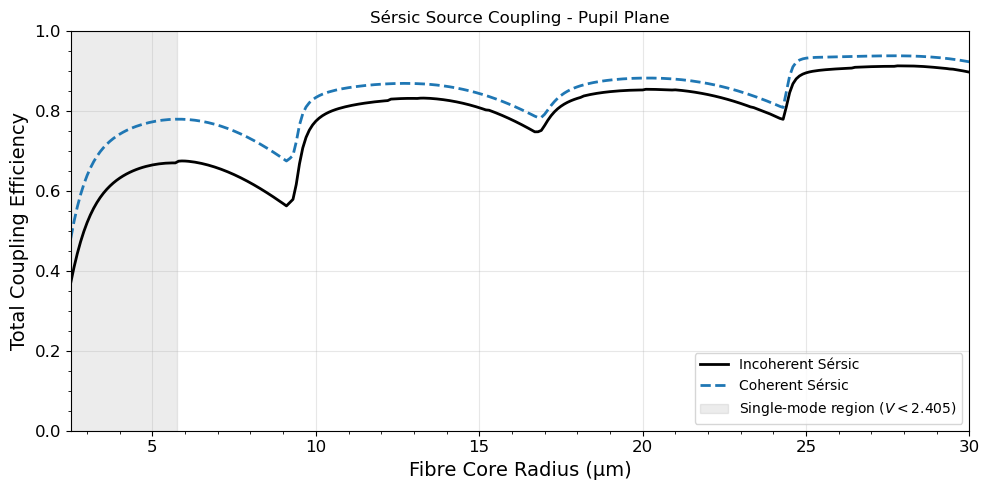

In [232]:
plt.figure(figsize=(10, 5))

plt.plot(
    core_radius_range * 1e6,
    eta_sersic_incoherent,
    label="Incoherent Sérsic",
    color="black",
    linewidth=2
)

plt.plot(
    core_radius_range * 1e6,
    eta_sersic_coherent,
    label="Coherent Sérsic",
    color="tab:blue",
    linestyle="--",
    linewidth=2
)

# Shade the single-mode region
plt.axvspan(
    0,
    a_max_single * 1e6,
    color="grey",
    alpha=0.15,
    label=r"Single-mode region ($V<2.405$)"
)

plt.xlabel("Fibre Core Radius (µm)", fontsize=14)
plt.ylabel("Total Coupling Efficiency", fontsize=14)
plt.title("Sérsic Source Coupling - Pupil Plane")

plt.tick_params(axis="both", labelsize=12)
plt.minorticks_on()
plt.grid(True, alpha=0.3)
plt.legend()

plt.ylim(0, 1)
plt.xlim(core_radius_range[0]*1e6, core_radius_range[-1]*1e6)

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Total coupling efficiency')

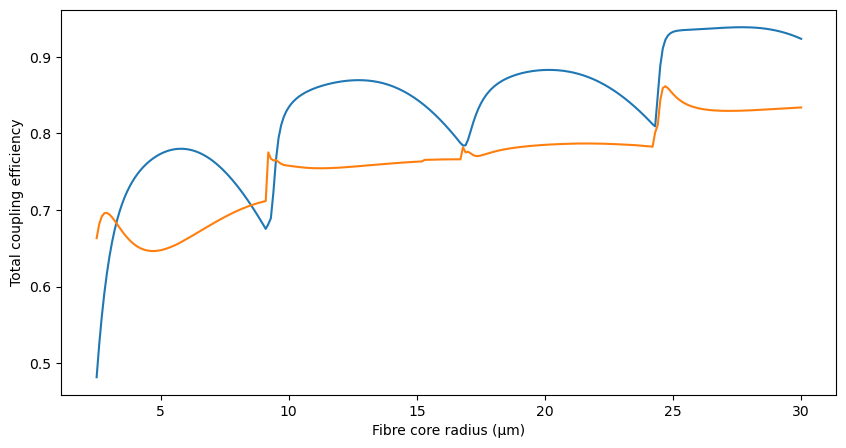

In [254]:
plt.figure(figsize=(10, 5))
plt.plot(core_radius_range*1e6, eta_sersic_coherent)
plt.plot(core_radius_range*1e6, eta_tot)

plt.xlabel("Fibre core radius (µm)")
plt.ylabel("Total coupling efficiency")